df HESTA provenances avec les principales villes suisse a analyser


In [ ]:
#from google.colab import drive
#drive.mount('/content/drive')

# **EDA**
**Top marché les 3-4 dernières années ?** (évolution) on peut aussi mettre le top marché de 2013 voir s’il y a des gros changements ?? (stacked bar chart)

**Taux d’occupation par mois les 3-4 dernières années**, pour savoir quels sont les mois pour lesquels il faut augmenter la demande  (line chart avec une ligne par année)

**Nuitées moyennes** par mois

Quels sont les marchés qui viennent déjà pendant la saison creuse

**Taux d’occupation dans les villes concurrentes suisse ou/et europe** (Lines chart) si une/des villes ont une meilleure répartition : Voir quels sont les marchés elles arrivent à attirer en basse saison

Data **aéroport **: un marché est intéressant que s’il y a des vols directs à destination de geneve pendant la basse saison


In [ ]:
!pip install pxweb

In [ ]:
import requests as r
import pandas as pd


In [ ]:
years = [ "2013", "2014"
"2015","2016","2017","2018","2019",
"2022","2023","2024","2025"
]

In [ ]:
communes = {
"261": "Zürich",
"3856": "Interlaken",
"3866": "Matten bei Interlaken",
"1061": "Luzern",
"2701": "Basel",
"3203": "St Gallen",
"3786": "St Moritz",
"3851": "Davos",
"5113": "Locarno",
"5586": "Lausanne",
"5661": "Château-d'Oex",
"5886": "Montreux",
"6024": "Nendaz",
"6288": "Saas-Fee",
"6290": "Zermatt",
"6621": "Genève",
"351": "Bern"
}

pour gérer le crash out

In [ ]:
import requests
import pandas as pd
from io import StringIO
import time

url = "https://www.pxweb.bfs.admin.ch/api/v1/fr/px-x-1003020000_101/px-x-1003020000_101.px"

dfs = []

for code, name in communes.items():

    print("Téléchargement :", name)

    data = {
      "query": [

        {
          "code": "Jahr",
          "selection": {
            "filter": "item",
            "values": years
          }
        },

        {
          "code": "Monat",
          "selection": {
            "filter": "all",
            "values": ["*"]
          }
        },

        {
          "code": "Gemeinde",
          "selection": {
            "filter": "item",
            "values": [code]
          }
        },

        {
          "code": "Herkunftsland",
          "selection": {
            "filter": "all",
            "values": ["*"]
          }
        }

      ],

      "response": {
        "format": "csv"
      }

    }

    success = False
    attempts = 0

    while not success and attempts < 5:

        try:

            r = requests.post(url, json=data, timeout=120)

            df = pd.read_csv(StringIO(r.text))

            df["Commune_nom"] = name

            dfs.append(df)

            success = True

            # sauvegarde intermédiaire
            df_temp = pd.concat(dfs, ignore_index=True)
            df_temp.to_csv("tourisme_backup.csv", index=False)

            print("✔ Sauvegarde effectuée")

        except Exception as e:

            attempts += 1
            print("Erreur → retry", attempts)
            time.sleep(5)

    if not success:
        print("⚠️ Impossible de télécharger :", name)

df = pd.concat(dfs, ignore_index=True)

# sauvegarde finale
df.to_csv("tourisme_final.csv", index=False)

print("Téléchargement terminé")
print(df.shape)

Téléchargement : Zürich
✔ Sauvegarde effectuée
Téléchargement : Interlaken
✔ Sauvegarde effectuée
Téléchargement : Matten bei Interlaken
✔ Sauvegarde effectuée
Téléchargement : Luzern
✔ Sauvegarde effectuée
Téléchargement : Basel
✔ Sauvegarde effectuée
Téléchargement : St Gallen
✔ Sauvegarde effectuée
Téléchargement : St Moritz
✔ Sauvegarde effectuée
Téléchargement : Davos
✔ Sauvegarde effectuée
Téléchargement : Locarno
✔ Sauvegarde effectuée
Téléchargement : Lausanne
✔ Sauvegarde effectuée
Téléchargement : Château-d'Oex
✔ Sauvegarde effectuée
Téléchargement : Montreux
✔ Sauvegarde effectuée
Téléchargement : Nendaz
✔ Sauvegarde effectuée
Téléchargement : Saas-Fee
✔ Sauvegarde effectuée
Téléchargement : Zermatt
✔ Sauvegarde effectuée
Téléchargement : Genève
✔ Sauvegarde effectuée
Téléchargement : Bern
✔ Sauvegarde effectuée
Téléchargement terminé
(0, 2)


In [ ]:
import requests
import pandas as pd
from io import StringIO
import time

url = "https://www.pxweb.bfs.admin.ch/api/v1/fr/px-x-1003020000_101/px-x-1003020000_101.px"

years = [ "2013", "2014","2015","2016","2017","2018","2019","2022","2023","2024","2025"]

communes = {
    "261": "Zürich", "3856": "Interlaken", "3866": "Matten bei Interlaken",
    "1061": "Luzern", "2701": "Basel", "3203": "St Gallen",
    "3786": "St Moritz", "3851": "Davos", "5113": "Locarno",
    "5586": "Lausanne", "5661": "Château-d'Oex", "5886": "Montreux",
    "6024": "Nendaz", "6288": "Saas-Fee", "6290": "Zermatt", "6621": "Genève","351": "Bern"
}

dfs = []

for code, name in communes.items():
    print("Téléchargement :", name)
    data = {
      "query": [
        {"code": "Jahr", "selection": {"filter": "item", "values": years}},
        {"code": "Monat", "selection": {"filter": "all", "values": ["*"]}},
        {"code": "Gemeinde", "selection": {"filter": "item", "values": [code]}},
        {"code": "Herkunftsland", "selection": {"filter": "all", "values": ["*"]}}
      ],
      "response": {"format": "csv"}
    }

    success = False
    attempts = 0
    while not success and attempts < 5:
        try:
            r = requests.post(url, json=data, timeout=120)
            df_temp = pd.read_csv(StringIO(r.text))
            df_temp["Commune_nom"] = name
            dfs.append(df_temp)
            success = True
            print("✔", name)
        except Exception as e:
            attempts += 1
            print("Erreur → retry", attempts, e)
            time.sleep(5)

    if not success:
        print("⚠️ Impossible :", name)
    time.sleep(1)  # éviter de spammer l'API

df = pd.concat(dfs, ignore_index=True)
df.to_csv("tourisme_final.csv", index=False)
print("\n✅ Téléchargement terminé")
print(df.shape)
df.head()

Téléchargement : Zürich
✔ Zürich
Téléchargement : Interlaken
✔ Interlaken
Téléchargement : Matten bei Interlaken
✔ Matten bei Interlaken
Téléchargement : Luzern
✔ Luzern
Téléchargement : Basel
✔ Basel
Téléchargement : St Gallen
✔ St Gallen
Téléchargement : St Moritz
✔ St Moritz
Téléchargement : Davos
✔ Davos
Téléchargement : Locarno
✔ Locarno
Téléchargement : Lausanne
✔ Lausanne
Téléchargement : Château-d'Oex
✔ Château-d'Oex
Téléchargement : Montreux
✔ Montreux
Téléchargement : Nendaz
✔ Nendaz
Téléchargement : Saas-Fee
✔ Saas-Fee
Téléchargement : Zermatt
✔ Zermatt
Téléchargement : Genève
✔ Genève
Téléchargement : Bern
✔ Bern

✅ Téléchargement terminé
(1859, 151)


,Année,Mois,Commune,Pays de provenance - total Arrivées,Pays de provenance - total Nuitées,Suisse Arrivées,Suisse Nuitées,Allemagne Arrivées,Allemagne Nuitées,France Arrivées,...,Slovénie Arrivées,Slovénie Nuitées,Tchéquie Arrivées,Tchéquie Nuitées,Ukraine Arrivées,Ukraine Nuitées,Serbie Arrivées,Serbie Nuitées,Commune_nom,Bad Request
0,2013.0,Total de l'année,Zürich,1579867.0,2830003.0,369334.0,586288.0,225766,388580,45660.0,...,1361,2535,4975,10885,5748,13660,3022,5349,Zürich,NaN
1,2013.0,Janvier,Zürich,100632.0,181631.0,25728.0,40846.0,15677,27533,3273.0,...,99,196,310,672,564,1310,239,438,Zürich,NaN
2,2013.0,Février,Zürich,97826.0,174816.0,25084.0,40376.0,15938,27551,3190.0,...,92,179,294,697,434,1055,182,357,Zürich,NaN
3,2013.0,Mars,Zürich,120931.0,211512.0,30317.0,48438.0,19286,32658,3709.0,...,111,184,478,891,570,1298,284,515,Zürich,NaN
4,2013.0,Avril,Zürich,122964.0,221251.0,27452.0,44723.0,19004,31404,3599.0,...,107,210,380,658,429,1151,409,686,Zürich,NaN


In [ ]:

print(df.head())
print(df.shape)


    Année              Mois Commune  Pays de provenance - total Arrivées  \
0  2013.0  Total de l'année  Zürich                            1579867.0   
1  2013.0           Janvier  Zürich                             100632.0   
2  2013.0           Février  Zürich                              97826.0   
3  2013.0              Mars  Zürich                             120931.0   
4  2013.0             Avril  Zürich                             122964.0   

   Pays de provenance - total Nuitées  Suisse Arrivées  Suisse Nuitées  \
0                           2830003.0         369334.0        586288.0   
1                            181631.0          25728.0         40846.0   
2                            174816.0          25084.0         40376.0   
3                            211512.0          30317.0         48438.0   
4                            221251.0          27452.0         44723.0   

  Allemagne Arrivées Allemagne Nuitées  France Arrivées  ...  \
0             225766            38

In [ ]:
df.columns

Index(['Année', 'Mois', 'Commune', 'Pays de provenance - total Arrivées',
       'Pays de provenance - total Nuitées', 'Suisse Arrivées',
       'Suisse Nuitées', 'Allemagne Arrivées', 'Allemagne Nuitées',
       'France Arrivées',
       ...
       'Slovénie Arrivées', 'Slovénie Nuitées', 'Tchéquie Arrivées',
       'Tchéquie Nuitées', 'Ukraine Arrivées', 'Ukraine Nuitées',
       'Serbie Arrivées', 'Serbie Nuitées', 'Commune_nom', 'Bad Request'],
      dtype='object', length=151)

In [ ]:
df = df.drop(columns=["Bad Request"], errors="ignore")

In [ ]:
df.head(14)

,Année,Mois,Commune,Pays de provenance - total Arrivées,Pays de provenance - total Nuitées,Suisse Arrivées,Suisse Nuitées,Allemagne Arrivées,Allemagne Nuitées,France Arrivées,...,Slovaquie Nuitées,Slovénie Arrivées,Slovénie Nuitées,Tchéquie Arrivées,Tchéquie Nuitées,Ukraine Arrivées,Ukraine Nuitées,Serbie Arrivées,Serbie Nuitées,Commune_nom
0,2013.0,Total de l'année,Zürich,1579867.0,2830003.0,369334.0,586288.0,225766,388580,45660.0,...,4786,1361,2535,4975,10885,5748,13660,3022,5349,Zürich
1,2013.0,Janvier,Zürich,100632.0,181631.0,25728.0,40846.0,15677,27533,3273.0,...,307,99,196,310,672,564,1310,239,438,Zürich
2,2013.0,Février,Zürich,97826.0,174816.0,25084.0,40376.0,15938,27551,3190.0,...,370,92,179,294,697,434,1055,182,357,Zürich
3,2013.0,Mars,Zürich,120931.0,211512.0,30317.0,48438.0,19286,32658,3709.0,...,419,111,184,478,891,570,1298,284,515,Zürich
4,2013.0,Avril,Zürich,122964.0,221251.0,27452.0,44723.0,19004,31404,3599.0,...,322,107,210,380,658,429,1151,409,686,Zürich
5,2013.0,Mai,Zürich,143393.0,254651.0,31341.0,47605.0,22534,38906,4014.0,...,312,72,139,366,710,527,1338,299,479,Zürich
6,2013.0,Juin,Zürich,153866.0,277179.0,32025.0,51226.0,19679,33962,3904.0,...,439,139,243,343,764,404,1030,299,474,Zürich
7,2013.0,Juillet,Zürich,156726.0,283204.0,29660.0,49749.0,19755,34611,4198.0,...,431,111,190,429,819,489,1144,166,271,Zürich
8,2013.0,Août,Zürich,156648.0,290555.0,31754.0,51667.0,19963,35098,3970.0,...,343,94,154,496,970,505,1124,164,285,Zürich
9,2013.0,Septembre,Zürich,147049.0,262895.0,34224.0,54609.0,19927,34135,3672.0,...,498,143,277,425,890,401,890,281,509,Zürich


In [ ]:
df.columns

Index(['Année', 'Mois', 'Commune', 'Pays de provenance - total Arrivées',
       'Pays de provenance - total Nuitées', 'Suisse Arrivées',
       'Suisse Nuitées', 'Allemagne Arrivées', 'Allemagne Nuitées',
       'France Arrivées',
       ...
       'Slovaquie Nuitées', 'Slovénie Arrivées', 'Slovénie Nuitées',
       'Tchéquie Arrivées', 'Tchéquie Nuitées', 'Ukraine Arrivées',
       'Ukraine Nuitées', 'Serbie Arrivées', 'Serbie Nuitées', 'Commune_nom'],
      dtype='object', length=150)

à transformer en tidy dataset (df_tidy)


In [ ]:
import pandas as pd
df = pd.read_csv("tourisme_final.csv")
print(df.shape)
print(df.columns.tolist()[:8])
df.head()

(1859, 151)
['Année', 'Mois', 'Commune', 'Pays de provenance - total Arrivées', 'Pays de provenance - total Nuitées', 'Suisse Arrivées', 'Suisse Nuitées', 'Allemagne Arrivées']


,Année,Mois,Commune,Pays de provenance - total Arrivées,Pays de provenance - total Nuitées,Suisse Arrivées,Suisse Nuitées,Allemagne Arrivées,Allemagne Nuitées,France Arrivées,...,Slovénie Arrivées,Slovénie Nuitées,Tchéquie Arrivées,Tchéquie Nuitées,Ukraine Arrivées,Ukraine Nuitées,Serbie Arrivées,Serbie Nuitées,Commune_nom,Bad Request
0,2013.0,Total de l'année,Zürich,1579867.0,2830003.0,369334.0,586288.0,225766,388580,45660.0,...,1361,2535,4975,10885,5748,13660,3022,5349,Zürich,NaN
1,2013.0,Janvier,Zürich,100632.0,181631.0,25728.0,40846.0,15677,27533,3273.0,...,99,196,310,672,564,1310,239,438,Zürich,NaN
2,2013.0,Février,Zürich,97826.0,174816.0,25084.0,40376.0,15938,27551,3190.0,...,92,179,294,697,434,1055,182,357,Zürich,NaN
3,2013.0,Mars,Zürich,120931.0,211512.0,30317.0,48438.0,19286,32658,3709.0,...,111,184,478,891,570,1298,284,515,Zürich,NaN
4,2013.0,Avril,Zürich,122964.0,221251.0,27452.0,44723.0,19004,31404,3599.0,...,107,210,380,658,429,1151,409,686,Zürich,NaN


In [ ]:
# copie du dataset original
df_tidy = df.copy()

# colonnes d'identification
id_vars = ["Année", "Mois", "Commune", "Commune_nom"]

# toutes les autres colonnes
value_vars = [col for col in df_tidy.columns if col not in id_vars]

# passer du format large au format long
df_long = df_tidy.melt(
    id_vars=id_vars,
    value_vars=value_vars,
    var_name="variable",
    value_name="valeur"
)

# séparer pays et type (Arrivées / Nuitées)
df_long[["Pays", "Type"]] = df_long["variable"].str.rsplit(" ", n=1, expand=True)

# supprimer la colonne intermédiaire
df_long = df_long.drop(columns="variable")

# remettre Arrivées et Nuitées en colonnes
df_tidy = df_long.pivot_table(
    index=["Année", "Mois", "Commune", "Commune_nom", "Pays"],
    columns="Type",
    values="valeur",
    aggfunc="sum"
).reset_index()

# enlever le nom de colonne généré par pivot
df_tidy.columns.name = None

df_tidy["Arrivées"] = (
    df_tidy["Arrivées"]
    .astype(str)
    .str.replace(" ", "")
    .str.replace(",", "")
)

df_tidy["Arrivées"] = pd.to_numeric(df_tidy["Arrivées"], errors="coerce")

# voir le résultat
df_tidy.head()

,Année,Mois,Commune,Commune_nom,Pays,Arrivées,Nuitées,Request
0,2013.0,Août,Basel,Basel,Afrique du Sud,68.0,161,NaN
1,2013.0,Août,Basel,Basel,Allemagne,10025.0,16109,NaN
2,2013.0,Août,Basel,Basel,Arabie saoudite,129.0,380,NaN
3,2013.0,Août,Basel,Basel,Argentine,35.0,80,NaN
4,2013.0,Août,Basel,Basel,Australie,497.0,1110,NaN


In [ ]:
df_tidy.columns

Index(['Année', 'Mois', 'Commune', 'Commune_nom', 'Pays', 'Arrivées',
       'Nuitées', 'Request'],
      dtype='object')

In [ ]:
df_tidy["Commune_nom"].unique()

array(['Basel', 'Bern', 'Davos', 'Genève', 'Lausanne', 'Locarno',
       'Luzern', 'Montreux', 'Nendaz', 'Zermatt', 'St Moritz',
       'St Gallen', 'Zürich'], dtype=object)

In [ ]:
print(df.shape)
print(df_tidy.shape)

(1859, 151)
(137566, 8)


**Analyse des arrivées**

1) segmenter les clients par nationnalité, idée: trouves les potentiels interessé à l'aide de moyenne annuel par nationnalité par année pour lausanne


In [ ]:
df_tidy.columns

Index(['Année', 'Mois', 'Commune', 'Commune_nom', 'Pays', 'Arrivées',
       'Nuitées', 'Request'],
      dtype='object')

In [ ]:
# sélectionner Lausanne
lausanne_df = df_tidy[df_tidy["Commune_nom"] == "Lausanne"]

# nombre de clients par nationalité et par année
clients_par_marche = (
    lausanne_df
    .groupby(["Année", "Pays"])["Arrivées"]
    .sum()
    .reset_index()
)

# afficher le résultat
clients_par_marche.sort_values(["Année", "Arrivées"], ascending=[True, False])

,Année,Pays,Arrivées
51,2013.0,Pays de provenance - total,727354.0
64,2013.0,Suisse,332232.0
29,2013.0,France,89292.0
38,2013.0,Italie,32750.0
58,2013.0,Royaume-Uni,32016.0
...,...,...,...
758,2025.0,Bélarus,246.0
790,2025.0,Oman,242.0
776,2025.0,Islande,210.0
754,2025.0,Bahreïn,198.0


In [ ]:
#plus gros marché pour lausanne:
lausanne_df.head()


,Année,Mois,Commune,Commune_nom,Pays,Arrivées,Nuitées,Request
296,2013.0,Août,Lausanne,Lausanne,Afrique du Sud,48.0,176,NaN
297,2013.0,Août,Lausanne,Lausanne,Allemagne,1662.0,3125,NaN
298,2013.0,Août,Lausanne,Lausanne,Arabie saoudite,464.0,1629,NaN
299,2013.0,Août,Lausanne,Lausanne,Argentine,32.0,147,NaN
300,2013.0,Août,Lausanne,Lausanne,Australie,194.0,460,NaN


In [ ]:

### Total depuis 2013 ????
top_marche = (
    lausanne_df
    .groupby("Pays")["Arrivées"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

top_marche.head(11)

,Pays,Arrivées
0,Pays de provenance - total,9742058.0
1,Suisse,4662958.0
2,France,1223224.0
3,États-Unis,492700.0
4,Allemagne,399434.0
5,Royaume-Uni,394624.0
6,Italie,332188.0
7,Chine,239464.0
8,Espagne,157516.0
9,Belgique,128004.0


In [ ]:
lausanne_total = df_tidy[df_tidy["Commune_nom"] == "Lausanne"]["Arrivées"].sum()

print("Total arrivées Lausanne :", lausanne_total)

Total arrivées Lausanne : 19484116.0


garder les marché interesasnt pour lausanne:

In [ ]:
top_markets = [
    "Suisse",
    "France",
    "États-Unis",
    "Allemagne",
    "Royaume-Uni",
    "Italie",
    "Chine",
    "Espagne",
    "Belgique",
    "Pays-Bas"
]
lausanne_df = df_tidy[df_tidy["Commune_nom"] == "Lausanne"]
lausanne_top = lausanne_df[lausanne_df["Pays"].isin(top_markets)]
lausanne_top["Pays"].unique()

array(['Allemagne', 'Belgique', 'Chine', 'Espagne', 'France', 'Italie',
       'Pays-Bas', 'Royaume-Uni', 'Suisse', 'États-Unis'], dtype=object)

In [ ]:
lausanne_top.groupby("Pays")["Arrivées"].sum().sort_values(ascending=False)

,Arrivées
Pays,
Suisse,4662958.0
France,1223224.0
États-Unis,492700.0
Allemagne,399434.0
Royaume-Uni,394624.0
Italie,332188.0
Chine,239464.0
Espagne,157516.0
Belgique,128004.0


heat map clients/années

In [ ]:
lausanne_heat = lausanne_top.groupby(["Pays","Année"])["Arrivées"].sum().reset_index()
heatmap_data = lausanne_heat.pivot(
    index="Pays",
    columns="Année",
    values="Arrivées"
)

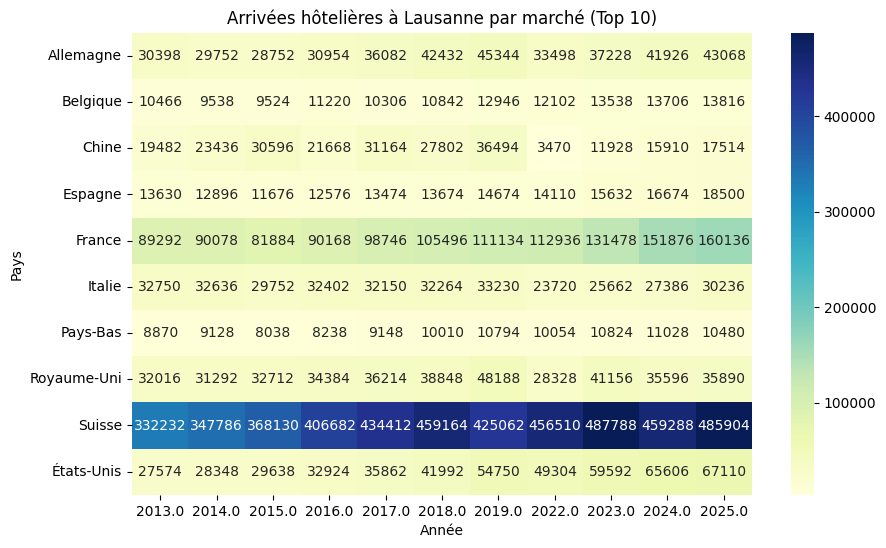

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Arrivées hôtelières à Lausanne par marché (Top 10)")
plt.ylabel("Pays")
plt.xlabel("Année")

plt.show()

moyenne de toutes les années

/tmp/ipykernel_1330/1489618480.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lausanne_month["Mois"] = pd.Categorical(
/tmp/ipykernel_1330/1489618480.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  lausanne_heat = lausanne_month.groupby(["Pays","Mois"])["Arrivées"].mean().reset_index()


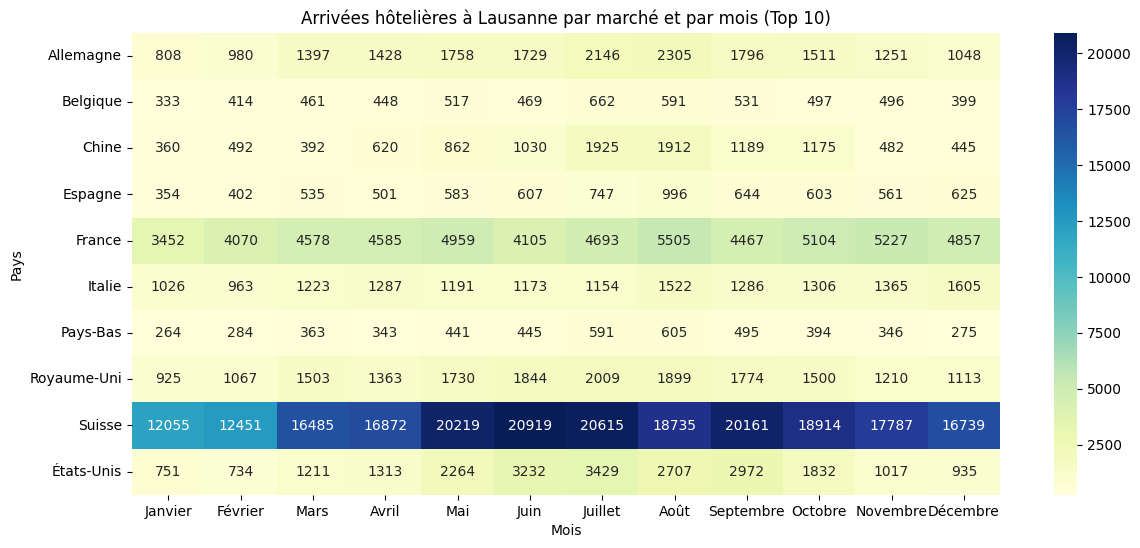

In [ ]:
# 1️⃣ enlever les totaux annuels
lausanne_month = lausanne_top[lausanne_top["Mois"] != "Total de l'année"]

# 2️⃣ ordre correct des mois
month_order = [
    "Janvier","Février","Mars","Avril","Mai","Juin",
    "Juillet","Août","Septembre","Octobre","Novembre","Décembre"
]

lausanne_month["Mois"] = pd.Categorical(
    lausanne_month["Mois"],
    categories=month_order,
    ordered=True
)

# 3️⃣ moyenne des arrivées par mois et par pays
lausanne_heat = lausanne_month.groupby(["Pays","Mois"])["Arrivées"].mean().reset_index()

# 4️⃣ pivot table
heatmap_data = lausanne_heat.pivot(
    index="Pays",
    columns="Mois",
    values="Arrivées"
)

# 5️⃣ heatmap

plt.figure(figsize=(14,6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Arrivées hôtelières à Lausanne par marché et par mois (Top 10)")
plt.ylabel("Pays")
plt.xlabel("Mois")

plt.show()

graphes analyse clients par nationnalité 2022

/tmp/ipykernel_1330/4246778726.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lausanne_2022["Mois"] = pd.Categorical(
/tmp/ipykernel_1330/4246778726.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  lausanne_heat_2022 = lausanne_2022.groupby(["Pays","Mois"])["Arrivées"].sum().reset_index()


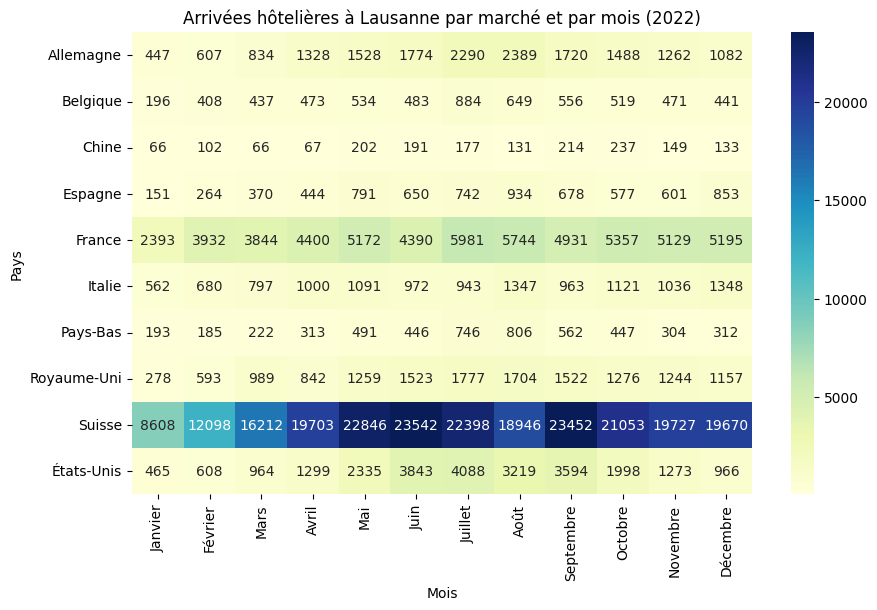

In [ ]:
# Filtrer Lausanne
lausanne_df = df_tidy[df_tidy["Commune_nom"] == "Lausanne"]

# garder seulement les top 10 marchés
lausanne_top = lausanne_df[lausanne_df["Pays"].isin(top_markets)]

# filtrer uniquement l'année 2022
lausanne_2022 = lausanne_top[lausanne_top["Année"] == 2022]

# ordre des mois
mois_ordre = [
    "Janvier","Février","Mars","Avril","Mai","Juin",
    "Juillet","Août","Septembre","Octobre","Novembre","Décembre"
]

lausanne_2022["Mois"] = pd.Categorical(
    lausanne_2022["Mois"],
    categories=mois_ordre,
    ordered=True
)

# préparation heatmap
lausanne_heat_2022 = lausanne_2022.groupby(["Pays","Mois"])["Arrivées"].sum().reset_index()

heatmap_2022 = lausanne_heat_2022.pivot(
    index="Pays",
    columns="Mois",
    values="Arrivées"
)

# graphique
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

sns.heatmap(
    heatmap_2022,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Arrivées hôtelières à Lausanne par marché et par mois (2022)")
plt.ylabel("Pays")
plt.xlabel("Mois")

plt.show()

graphes analyse clients par nationnalité 2023

/tmp/ipykernel_1330/700287444.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lausanne_2023["Mois"] = pd.Categorical(
/tmp/ipykernel_1330/700287444.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  lausanne_heat_2023 = lausanne_2023.groupby(["Pays","Mois"])["Arrivées"].sum().reset_index()


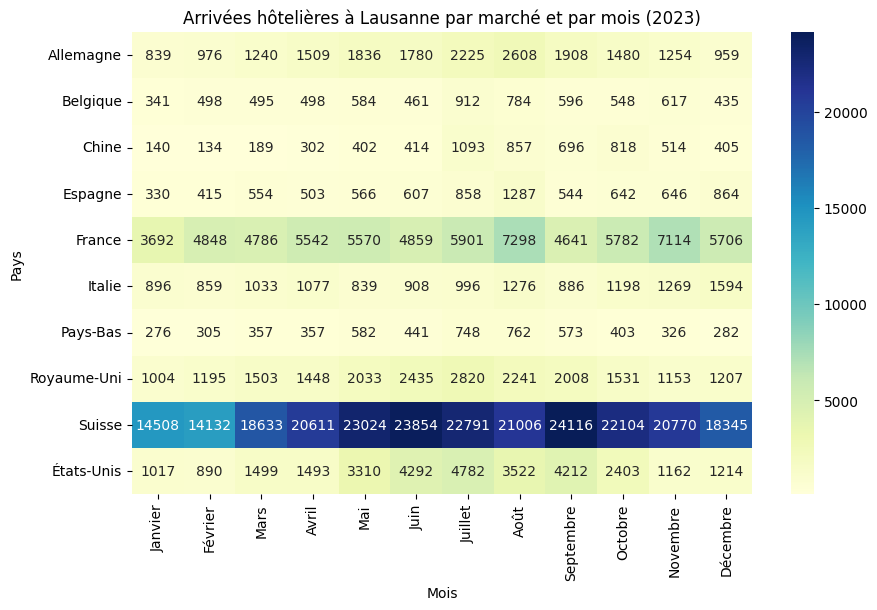

In [ ]:
# Filtrer Lausanne
lausanne_df = df_tidy[df_tidy["Commune_nom"] == "Lausanne"]

# garder seulement les top 10 marchés
lausanne_top = lausanne_df[lausanne_df["Pays"].isin(top_markets)]

# filtrer uniquement l'année 2023
lausanne_2023 = lausanne_top[lausanne_top["Année"] == 2023]

# ordre des mois
mois_ordre = [
    "Janvier","Février","Mars","Avril","Mai","Juin",
    "Juillet","Août","Septembre","Octobre","Novembre","Décembre"
]

lausanne_2023["Mois"] = pd.Categorical(
    lausanne_2023["Mois"],
    categories=mois_ordre,
    ordered=True
)

# préparation heatmap
lausanne_heat_2023 = lausanne_2023.groupby(["Pays","Mois"])["Arrivées"].sum().reset_index()

heatmap_2023 = lausanne_heat_2023.pivot(
    index="Pays",
    columns="Mois",
    values="Arrivées"
)

# graphique
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

sns.heatmap(
    heatmap_2023,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Arrivées hôtelières à Lausanne par marché et par mois (2023)")
plt.ylabel("Pays")
plt.xlabel("Mois")

plt.show()

graphes analyse clients par nationnalité 2024

/tmp/ipykernel_1330/1588796899.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lausanne_2024["Mois"] = pd.Categorical(
/tmp/ipykernel_1330/1588796899.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  lausanne_heat_2024 = lausanne_2024.groupby(["Pays","Mois"])["Arrivées"].sum().reset_index()


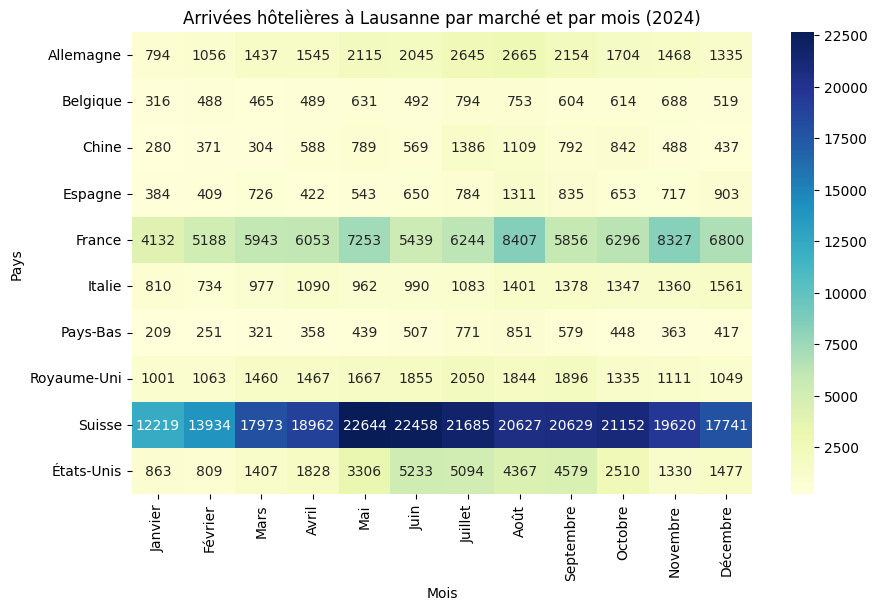

In [ ]:
# Filtrer Lausanne
lausanne_df = df_tidy[df_tidy["Commune_nom"] == "Lausanne"]

# garder seulement les top 10 marchés
lausanne_top = lausanne_df[lausanne_df["Pays"].isin(top_markets)]

# filtrer uniquement l'année 2024
lausanne_2024 = lausanne_top[lausanne_top["Année"] == 2024]

# ordre des mois
mois_ordre = [
    "Janvier","Février","Mars","Avril","Mai","Juin",
    "Juillet","Août","Septembre","Octobre","Novembre","Décembre"
]

lausanne_2024["Mois"] = pd.Categorical(
    lausanne_2024["Mois"],
    categories=mois_ordre,
    ordered=True
)

# préparation heatmap
lausanne_heat_2024 = lausanne_2024.groupby(["Pays","Mois"])["Arrivées"].sum().reset_index()

heatmap_2024 = lausanne_heat_2024.pivot(
    index="Pays",
    columns="Mois",
    values="Arrivées"
)

# graphique

plt.figure(figsize=(10,6))

sns.heatmap(
    heatmap_2024,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Arrivées hôtelières à Lausanne par marché et par mois (2024)")
plt.ylabel("Pays")
plt.xlabel("Mois")

plt.show()

evolution des fréquentation par nationnalité

/tmp/ipykernel_1330/1165474512.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lausanne_recent["Mois"] = pd.Categorical(


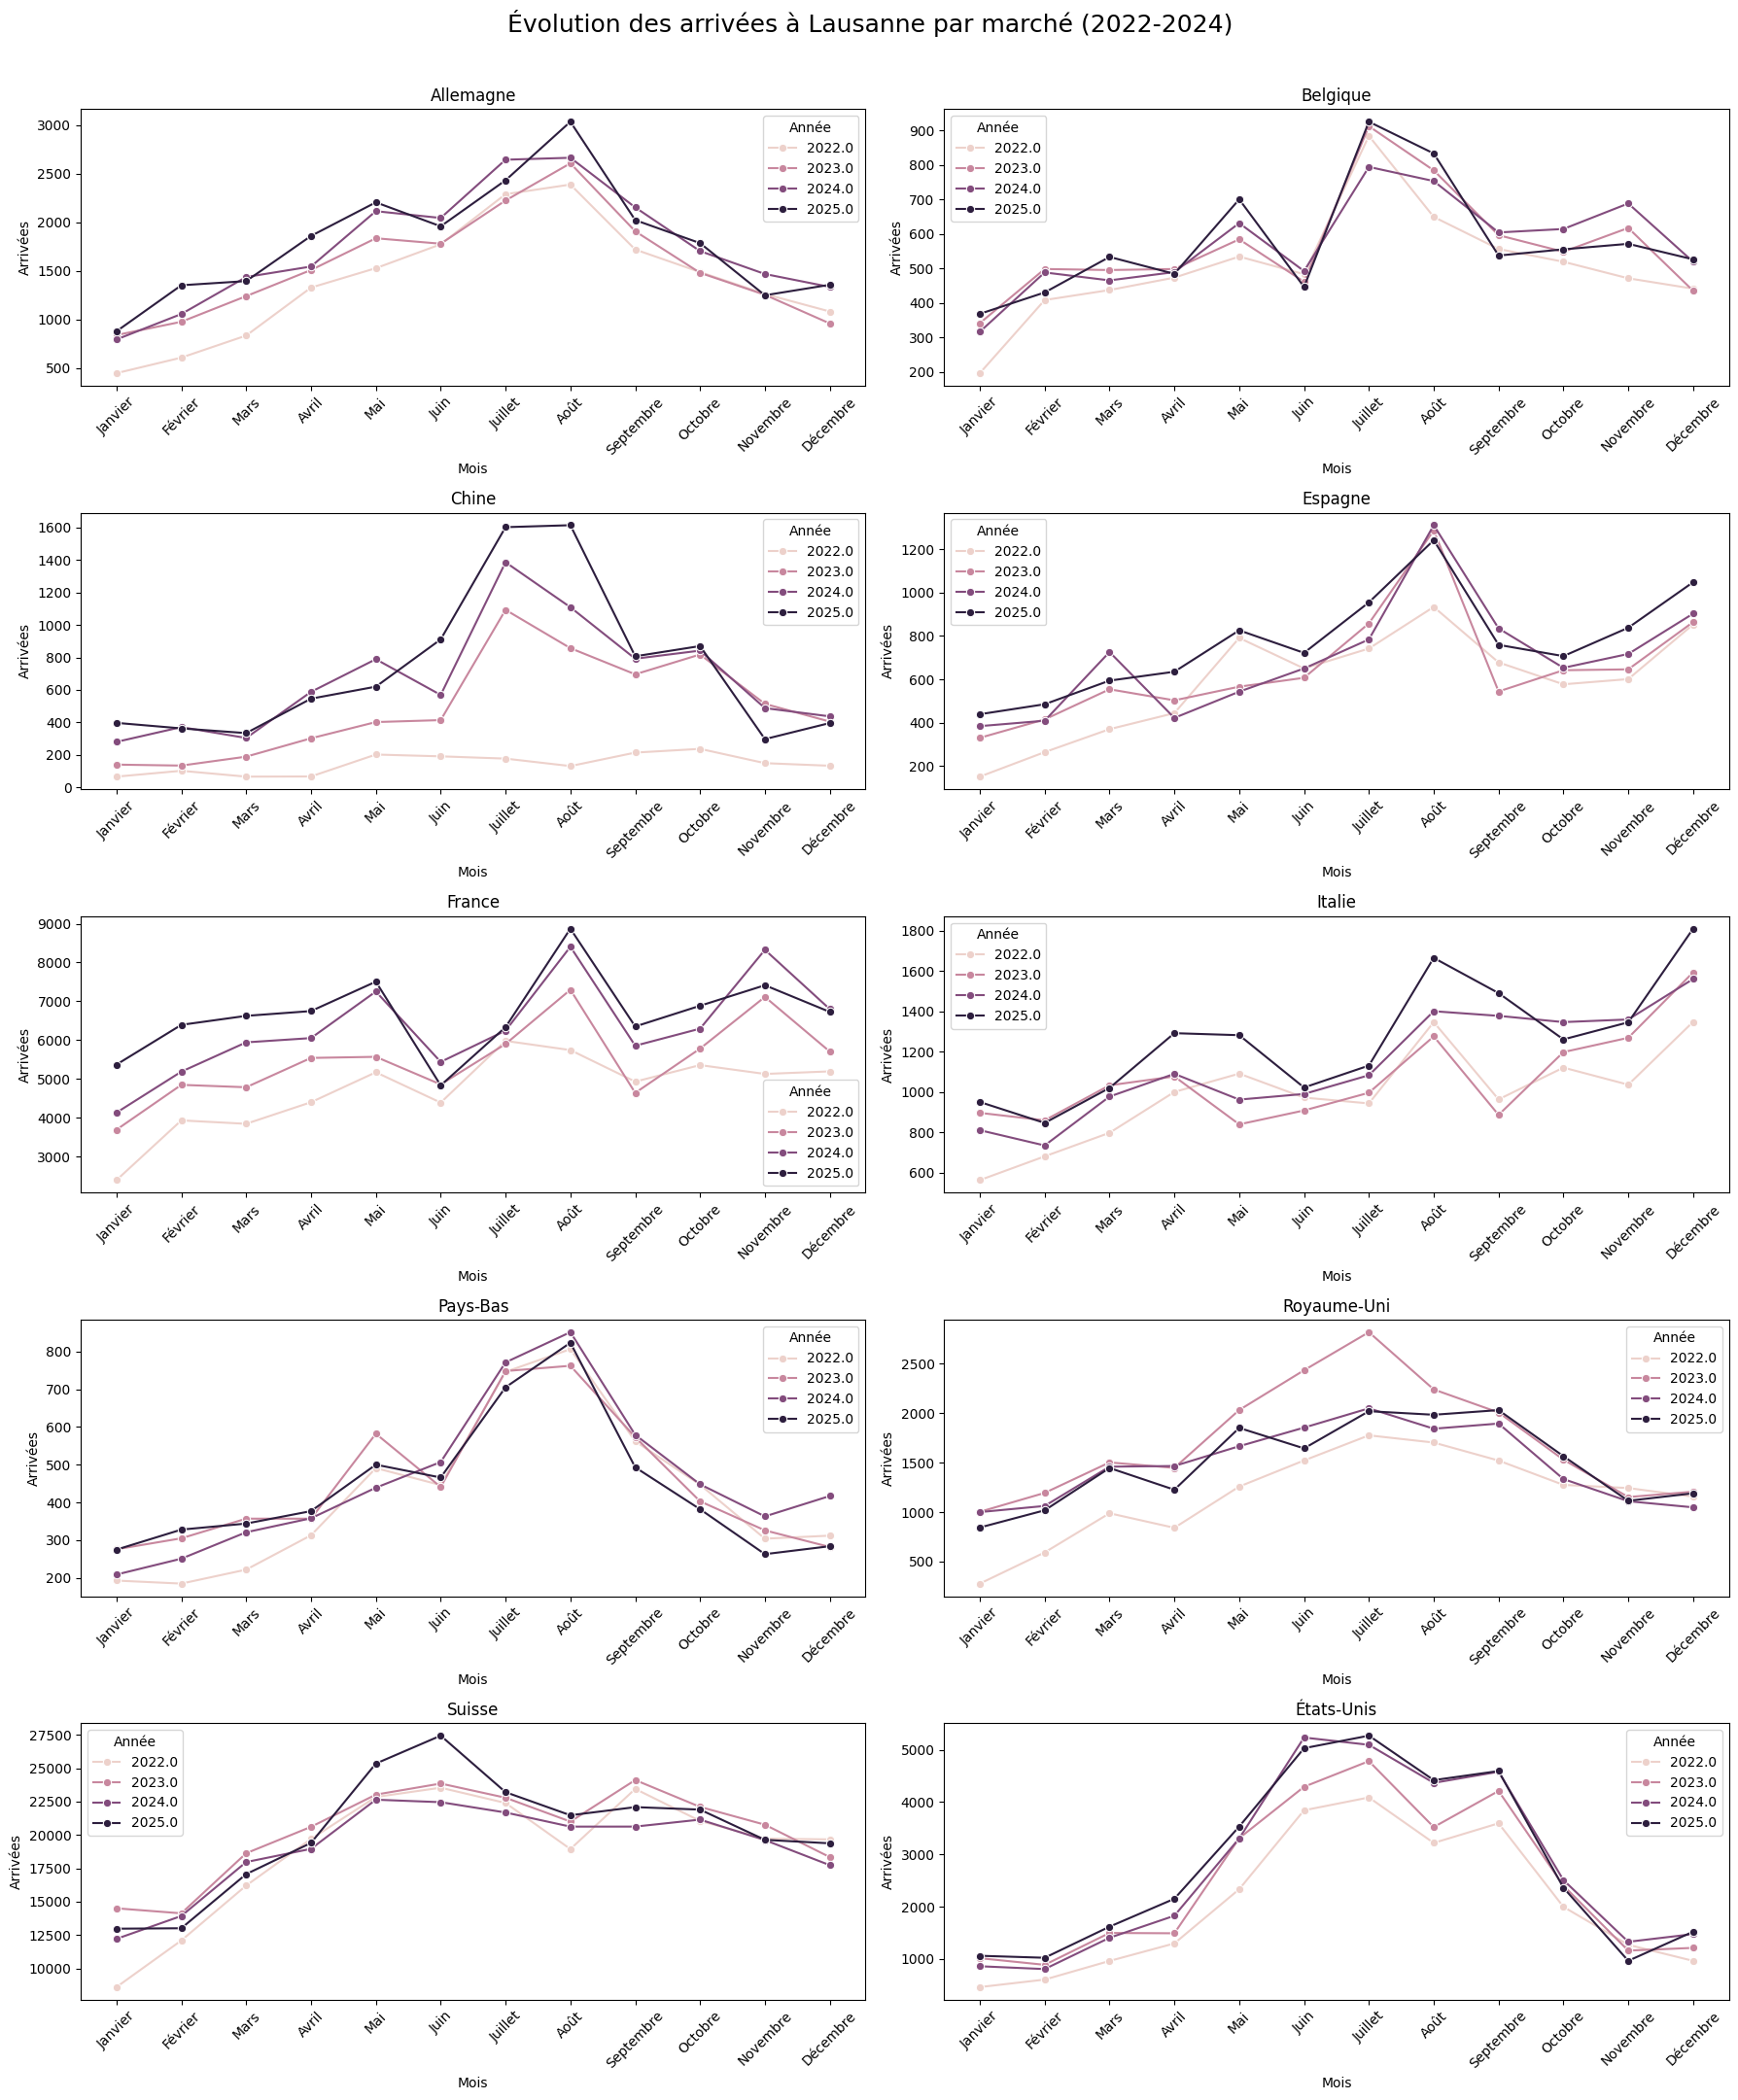

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# garder uniquement les années récentes
lausanne_recent = lausanne_top[lausanne_top["Année"].isin([2022, 2023, 2024, 2025])]

# ordre des mois
mois_ordre = [
    "Janvier","Février","Mars","Avril","Mai","Juin",
    "Juillet","Août","Septembre","Octobre","Novembre","Décembre"
]

lausanne_recent["Mois"] = pd.Categorical(
    lausanne_recent["Mois"],
    categories=mois_ordre,
    ordered=True
)

# liste des marchés
markets = lausanne_recent["Pays"].unique()

# création des 10 graphes
fig, axes = plt.subplots(5, 2, figsize=(18,22))  # ⬅️ plus grand
axes = axes.flatten()

for i, market in enumerate(markets):

    data_market = lausanne_recent[lausanne_recent["Pays"] == market]

    sns.lineplot(
        data=data_market,
        x="Mois",
        y="Arrivées",
        hue="Année",
        marker="o",
        ax=axes[i]
    )

    axes[i].set_title(market)
    axes[i].set_ylabel("Arrivées")
    axes[i].set_xlabel("Mois")

    # 🔧 rendre les mois lisibles
    axes[i].tick_params(axis='x', rotation=45)

plt.suptitle("Évolution des arrivées à Lausanne par marché (2022-2024)", fontsize=18)

# 🔧 évite que le titre chevauche
plt.tight_layout(rect=[0, 0, 1, 0.97])

plt.show()

**Analyse des nuitées**

In [ ]:
df_tidy["Nuitées"] = (
    df_tidy["Nuitées"]
    .astype(str)
    .str.replace(" ", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.replace("\xa0", "", regex=False)
)
df_tidy["Nuitées"] = pd.to_numeric(df_tidy["Nuitées"], errors="coerce")

In [ ]:
import pandas as pd

# Reconstruire df_hesta depuis df_tidy
df_hesta = (
    df_tidy
    .groupby(["Commune", "Année", "Mois"], as_index=False)["Nuitées"]
    .sum()
)

# Reconstruire df_provenance depuis df_tidy
df_arr = df_tidy.pivot_table(
    index=["Année", "Mois", "Commune"],
    columns="Pays",
    values="Arrivées",
    aggfunc="sum"
).reset_index()
df_arr.columns = [col if col in ["Année", "Mois", "Commune"] else f"{col} Arrivées" for col in df_arr.columns]
df_arr.columns.name = None

df_nuit = df_tidy.pivot_table(
    index=["Année", "Mois", "Commune"],
    columns="Pays",
    values="Nuitées",
    aggfunc="sum"
).reset_index()
df_nuit.columns = [col if col in ["Année", "Mois", "Commune"] else f"{col} Nuitées" for col in df_nuit.columns]
df_nuit.columns.name = None

df_provenance = df_arr.merge(df_nuit, on=["Année", "Mois", "Commune"])

display(df_hesta.head())
display(df_provenance.head())

,Commune,Année,Mois,Nuitées
0,Basel,2013.0,Août,189806.0
1,Basel,2013.0,Avril,206002.0
2,Basel,2013.0,Décembre,155540.0
3,Basel,2013.0,Février,155426.0
4,Basel,2013.0,Janvier,134416.0


,Année,Mois,Commune,Afrique du Sud Arrivées,Allemagne Arrivées,Arabie saoudite Arrivées,Argentine Arrivées,Australie Arrivées,Autres Afrique Arrivées,Autres Afrique du Nord Arrivées,...,Suisse Nuitées,Suède Nuitées,Taïwan (Taipei chinois) Nuitées,Tchéquie Nuitées,Thaïlande Nuitées,Turquie Nuitées,Ukraine Nuitées,Égypte Nuitées,Émirats arabes unis Nuitées,États-Unis Nuitées
0,2013.0,Août,Basel,68.0,10025.0,129.0,35.0,497.0,112.0,35.0,...,23770.0,604.0,428.0,436.0,119.0,598.0,84.0,81.0,810.0,9473.0
1,2013.0,Août,Bern,21.0,4495.0,136.0,76.0,241.0,57.0,17.0,...,31098.0,632.0,668.0,263.0,257.0,230.0,124.0,17.0,651.0,4019.0
2,2013.0,Août,Davos,4.0,10630.0,37.0,8.0,47.0,9.0,0.0,...,35153.0,112.0,24.0,672.0,10.0,18.0,2.0,0.0,39.0,988.0
3,2013.0,Août,Genève,187.0,2858.0,6795.0,201.0,1113.0,534.0,526.0,...,26366.0,925.0,319.0,456.0,327.0,986.0,829.0,1435.0,10912.0,12593.0
4,2013.0,Août,Lausanne,48.0,1662.0,464.0,32.0,194.0,142.0,67.0,...,28611.0,388.0,186.0,146.0,131.0,512.0,223.0,143.0,1140.0,3675.0


In [ ]:
# df_hesta a déjà les bonnes colonnes, pas besoin de renommer
# Garder seulement Lausanne
df_hesta_laus = df_hesta[df_hesta['Commune'] == 'Lausanne'].copy()

display(df_hesta_laus.head(10))

,Commune,Année,Mois,Nuitées
572,Lausanne,2013.0,Août,149892.0
573,Lausanne,2013.0,Avril,113920.0
574,Lausanne,2013.0,Décembre,96700.0
575,Lausanne,2013.0,Février,97214.0
576,Lausanne,2013.0,Janvier,90266.0
577,Lausanne,2013.0,Juillet,151704.0
578,Lausanne,2013.0,Juin,150942.0
579,Lausanne,2013.0,Mai,134816.0
580,Lausanne,2013.0,Mars,121650.0
581,Lausanne,2013.0,Novembre,118250.0


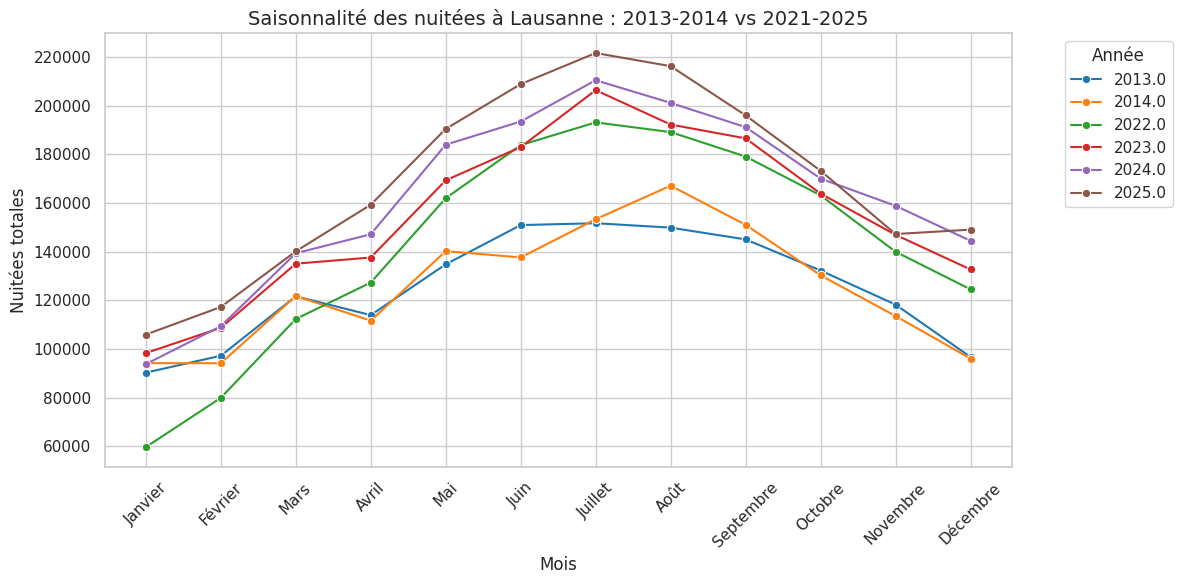

In [ ]:
# Paramètres d'affichage
sns.set_theme(style="whitegrid")

#copie pour ne pas modifier le graphe initial
df_graph1 = df_hesta_laus.copy()

# Enlever la ligne des totaux annuel
df_graph1 = df_graph1[df_graph1["Mois"] != "Total de l'année"]

# "Année" et "Nuitées" sont-elles bien reconnues comme des nombres ?
df_graph1["Année"] = pd.to_numeric(df_graph1["Année"])
df_graph1["Nuitées"] = pd.to_numeric(df_graph1["Nuitées"])

# Déterminer les années qu'on veut garder
annees_cible = [2013, 2014, 2021, 2022, 2023, 2024, 2025]
df_graph1 = df_graph1[df_graph1["Année"].isin(annees_cible)]

# Ordonner chronologiquement les mois
ordre_mois = ["Janvier", "Février", "Mars", "Avril", "Mai", "Juin", "Juillet", "Août", "Septembre", "Octobre", "Novembre", "Décembre"]
df_graph1["Mois"] = pd.Categorical(df_graph1["Mois"], categories=ordre_mois, ordered=True)

#  Création de la figure
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_graph1, x="Mois", y="Nuitées", hue="Année", palette="tab10", marker="o")
plt.title("Saisonnalité des nuitées à Lausanne : 2013-2014 vs 2021-2025", fontsize=14)
plt.xlabel("Mois", fontsize=12)
plt.ylabel("Nuitées totales", fontsize=12)
plt.xticks(rotation=45)
plt.legend(title="Année", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()

plt.show()

In [ ]:
# df_provenance a déjà les bonnes colonnes, pas besoin de renommer
# Suppression des lignes "Total de l'année"
df_provenance = df_provenance[df_provenance["Mois"] != "Total de l'année"]

df_provenance_laus = df_provenance[df_provenance["Commune"] == "Lausanne"].copy()
df_provenance_laus.head()

,Année,Mois,Commune,Afrique du Sud Arrivées,Allemagne Arrivées,Arabie saoudite Arrivées,Argentine Arrivées,Australie Arrivées,Autres Afrique Arrivées,Autres Afrique du Nord Arrivées,...,Suisse Nuitées,Suède Nuitées,Taïwan (Taipei chinois) Nuitées,Tchéquie Nuitées,Thaïlande Nuitées,Turquie Nuitées,Ukraine Nuitées,Égypte Nuitées,Émirats arabes unis Nuitées,États-Unis Nuitées
4,2013.0,Août,Lausanne,48.0,1662.0,464.0,32.0,194.0,142.0,67.0,...,28611.0,388.0,186.0,146.0,131.0,512.0,223.0,143.0,1140.0,3675.0
17,2013.0,Avril,Lausanne,19.0,1302.0,41.0,37.0,136.0,104.0,105.0,...,21832.0,564.0,87.0,110.0,248.0,306.0,250.0,99.0,246.0,3037.0
30,2013.0,Décembre,Lausanne,52.0,806.0,23.0,22.0,122.0,68.0,53.0,...,21393.0,228.0,21.0,111.0,81.0,278.0,130.0,125.0,216.0,1657.0
43,2013.0,Février,Lausanne,22.0,1063.0,24.0,40.0,119.0,94.0,60.0,...,18261.0,475.0,58.0,138.0,86.0,428.0,277.0,86.0,199.0,1988.0
56,2013.0,Janvier,Lausanne,31.0,891.0,37.0,53.0,178.0,142.0,44.0,...,16799.0,338.0,60.0,131.0,39.0,255.0,215.0,81.0,186.0,2164.0


/tmp/ipykernel_1330/4284237818.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_groupe_arr = df_recent_arr.groupby(["Mois", "Marché_Regroupé"])["Arrivées"].mean().unstack()


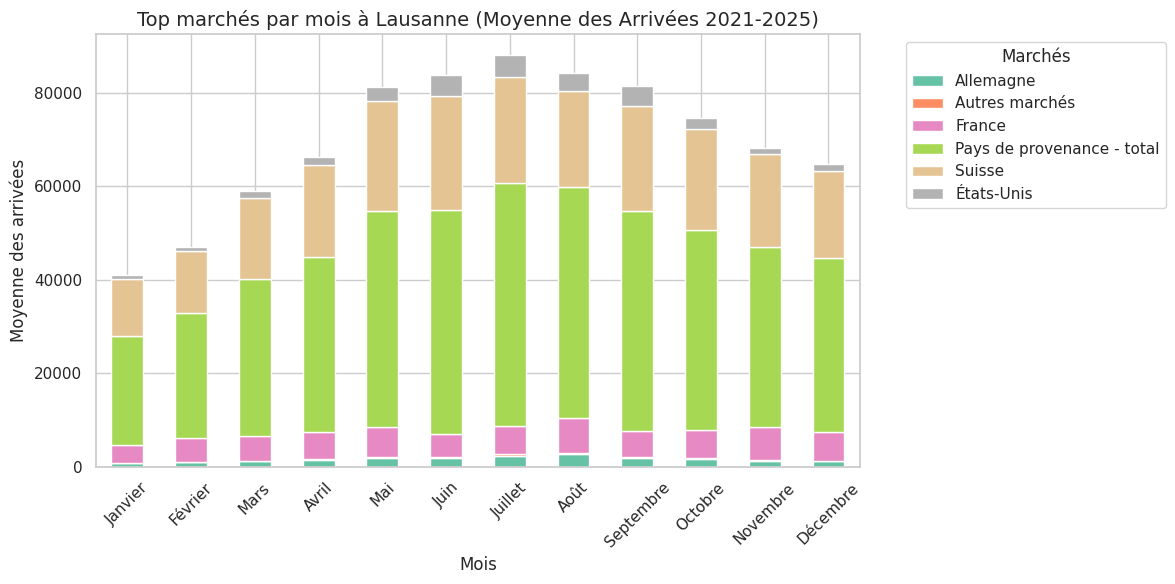

In [ ]:
# Isoler colonnes arrivées
colonnes_arrivees = [col for col in df_provenance_laus.columns if str(col).endswith("Arrivées") and col != "Total Arrivées"]
df_arr = df_provenance_laus[["Année", "Mois"] + colonnes_arrivees].copy()

# convertir en nbres
for col in colonnes_arrivees:
    df_arr[col] = pd.to_numeric(df_arr[col], errors="coerce").fillna(0)

# Melt tableau
df_long_arr = pd.melt(df_arr, id_vars=["Année", "Mois"], var_name="Marché", value_name="Arrivées")
df_long_arr["Marché"] = df_long_arr["Marché"].str.replace(" Arrivées", "")

# Définir les années qu'on veut analyser
df_long_arr["Année"] = pd.to_numeric(df_long_arr["Année"])
df_recent_arr = df_long_arr[df_long_arr["Année"].isin([2021, 2022, 2023, 2024, 2025])].copy()

top_5_marches = df_recent_arr.groupby("Marché")["Arrivées"].sum().nlargest(5).index.tolist()
df_recent_arr["Marché_Regroupé"] = df_recent_arr["Marché"].apply(lambda x: x if x in top_5_marches else "Autres marchés")
ordre_mois = ["Janvier", "Février", "Mars", "Avril", "Mai", "Juin", "Juillet", "Août", "Septembre", "Octobre", "Novembre", "Décembre"]
df_recent_arr["Mois"] = pd.Categorical(df_recent_arr["Mois"], categories=ordre_mois, ordered=True)

# Créer graphique
df_groupe_arr = df_recent_arr.groupby(["Mois", "Marché_Regroupé"])["Arrivées"].mean().unstack()
df_groupe_arr.plot(kind="bar", stacked=True, figsize=(12, 6), colormap="Set2")

plt.title("Top marchés par mois à Lausanne (Moyenne des Arrivées 2021-2025)", fontsize=14)
plt.xlabel("Mois", fontsize=12)
plt.ylabel("Moyenne des arrivées", fontsize=12)
plt.xticks(rotation=45)
plt.legend(title="Marchés", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [ ]:
donnees_tableau = []
df_provenance_laus["Année"] = pd.to_numeric(df_provenance_laus["Année"], errors="coerce")
# On filtre le dataframe d'origine pour la même période (2021-2025)
df_prov_recent = df_provenance_laus[df_provenance_laus["Année"].isin([2021, 2022, 2023, 2024, 2025])].copy()

for marche in top_5_marches:
    col_arr = f"{marche} Arrivées"
    col_nuit = f"{marche} Nuitées"

    # calcule de la moyenne mensuelle des arrivées et des nuitées
    moyenne_arr = pd.to_numeric(df_prov_recent[col_arr], errors="coerce").mean()
    moyenne_nuit = pd.to_numeric(df_prov_recent[col_nuit], errors="coerce").mean()

    # Calcule DMS (durée moyenne de séjour)
    dms = moyenne_nuit / moyenne_arr if moyenne_arr > 0 else 0

    donnees_tableau.append({
        "Marché (Top 5)": marche,
        "Arrivées Moyennes / mois": round(moyenne_arr, 0),
        "Nuitées Moyennes / mois": round(moyenne_nuit, 0),
        "Durée Moyenne de Séjour (Jours)": round(dms, 2)
    })


df_recapitulatif = pd.DataFrame(donnees_tableau)
display(df_recapitulatif)

,Marché (Top 5),Arrivées Moyennes / mois,Nuitées Moyennes / mois,Durée Moyenne de Séjour (Jours)
0,Pays de provenance - total,40194.0,78586.0,1.96
1,Suisse,19682.0,35428.0,1.80
2,France,5796.0,9802.0,1.69
3,États-Unis,2517.0,5782.0,2.30
4,Allemagne,1622.0,3217.0,1.98


In [ ]:
import pandas as pd

# définir les saisons
dico_saisons = {
    "Janvier": "3. Basse", "Février": "3. Basse", "Mars": "3. Basse", "Novembre": "3. Basse", "Décembre": "3. Basse",
    "Avril": "2. Moyenne", "Mai": "2. Moyenne", "Octobre": "2. Moyenne",
    "Juin": "1. Haute", "Juillet": "1. Haute", "Août": "1. Haute", "Septembre": "1. Haute"
}

df_saisons = df_provenance_laus.copy()
df_saisons["Saison"] = df_saisons["Mois"].map(dico_saisons)
df_saisons["Année"] = pd.to_numeric(df_saisons["Année"], errors="coerce")
df_recent_saisons = df_saisons[df_saisons["Année"].isin([2021, 2022, 2023, 2024, 2025])].copy()

tous_les_marches = [col.replace(" Arrivées", "") for col in df_provenance_laus.columns if str(col).endswith(" Arrivées") and col != "Total Arrivées"]


resultats_finaux = []
for saison in ["1. Haute", "2. Moyenne", "3. Basse"]:
    df_filtre = df_recent_saisons[df_recent_saisons["Saison"] == saison]

    donnees_saison_actuelle = []
    for marche in tous_les_marches:
        col_arr = f"{marche} Arrivées"
        col_nuit = f"{marche} Nuitées"
        # Moyennes mensuelles pendant cette saison
        moyenne_arr = pd.to_numeric(df_filtre[col_arr], errors="coerce").mean()
        moyenne_nuit = pd.to_numeric(df_filtre[col_nuit], errors="coerce").mean()
        # On ne garde que les marchés qui ont eu des visiteurs
        if moyenne_arr > 0:
            dms = moyenne_nuit / moyenne_arr
            donnees_saison_actuelle.append({
                "Saison": saison.replace("1. ", "").replace("2. ", "").replace("3. ", ""), # On nettoie le nom
                "Marché": marche,
                "Arrivées Moy. / mois": round(moyenne_arr, 0),
                "Nuitées Moy. / mois": round(moyenne_nuit, 0),
                "Durée de Séjour (DMS)": round(dms, 2)
            })

    df_stats_saison = pd.DataFrame(donnees_saison_actuelle)

    # Top 10
    top_10 = df_stats_saison.sort_values(by="Nuitées Moy. / mois", ascending=False).head(10)
    resultats_finaux.append(top_10)

df_tableau_saisons = pd.concat(resultats_finaux).reset_index(drop=True)
display(df_tableau_saisons.style.set_properties(**{"text-align": "center", "border": "1px solid black"}))

,Saison,Marché,Arrivées Moy. / mois,Nuitées Moy. / mois,Durée de Séjour (DMS)
0,Haute,Pays de provenance - total,49113.000000,98532.000000,2.010000
1,Haute,Suisse,22482.000000,41631.000000,1.850000
2,Haute,France,6005.000000,10467.000000,1.740000
3,Haute,États-Unis,4383.000000,9823.000000,2.240000
4,Haute,Allemagne,2228.000000,4340.000000,1.950000
5,Haute,Royaume-Uni,1960.000000,4147.000000,2.120000
6,Haute,Italie,1153.000000,2190.000000,1.900000
7,Haute,Espagne,847.000000,1856.000000,2.190000
8,Haute,Arabie saoudite,424.000000,1534.000000,3.610000
9,Haute,Belgique,669.000000,1391.000000,2.080000


/tmp/ipykernel_1330/2319489167.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=top_10_trie_dms, x="DMS", y="Marché", palette="mako")


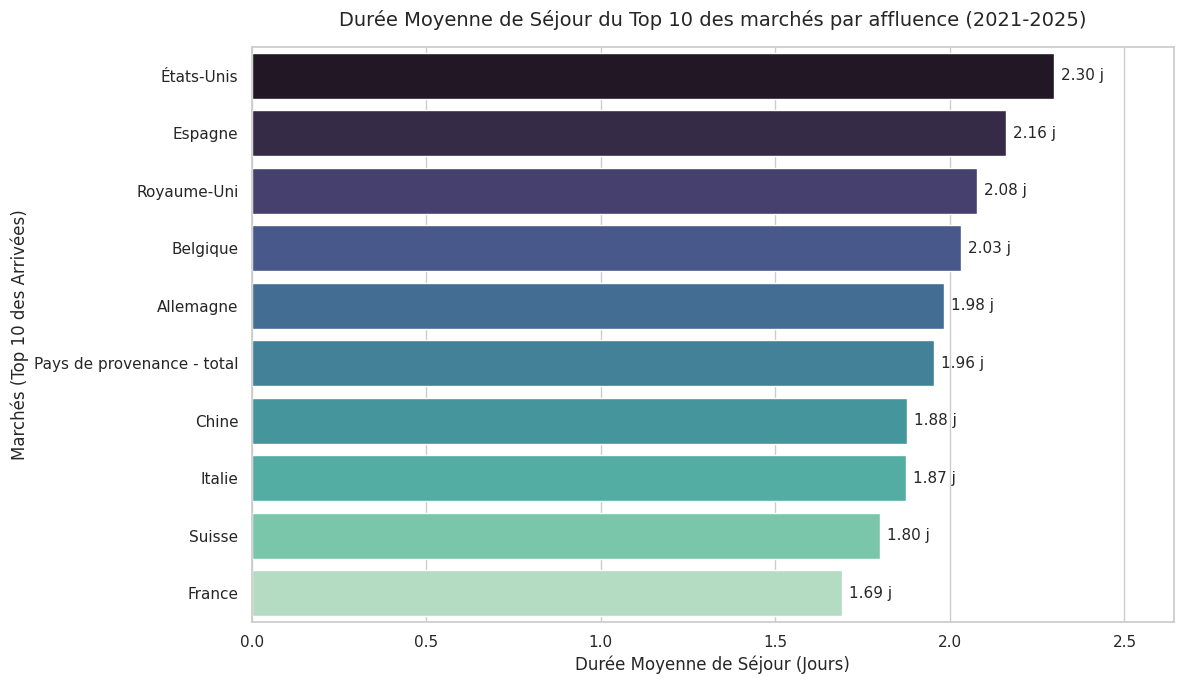

In [ ]:
df_prov_recent = df_provenance_laus.copy()
df_prov_recent["Année"] = pd.to_numeric(df_prov_recent["Année"], errors="coerce")
df_prov_recent = df_prov_recent[df_prov_recent["Année"].isin([2021, 2022, 2023, 2024, 2025])]

#Identifier tous les marchés disponibles
tous_les_marches = [col.replace(" Arrivées", "") for col in df_provenance_laus.columns if str(col).endswith(" Arrivées") and col != "Total Arrivées"]

donnees_marches = []

# Calculer les moyennes par marché
for marche in tous_les_marches:
    col_arr = f"{marche} Arrivées"
    col_nuit = f"{marche} Nuitées"

    moyenne_arr = pd.to_numeric(df_prov_recent[col_arr], errors="coerce").mean()
    moyenne_nuit = pd.to_numeric(df_prov_recent[col_nuit], errors="coerce").mean()

    if moyenne_arr > 0:
        dms = moyenne_nuit / moyenne_arr
        donnees_marches.append({
            "Marché": marche,
            "Arrivées Moyennes": moyenne_arr,
            "DMS": dms
        })

df_stats = pd.DataFrame(donnees_marches)

#  Top 10 selon arrivées
top_10_arrivees = df_stats.sort_values(by="Arrivées Moyennes", ascending=False).head(10).copy()

# DMS
top_10_trie_dms = top_10_arrivees.sort_values(by="DMS", ascending=False)

# Création du graphique
plt.figure(figsize=(12, 7))
sns.set_theme(style="whitegrid")
ax = sns.barplot(data=top_10_trie_dms, x="DMS", y="Marché", palette="mako")
plt.title("Durée Moyenne de Séjour du Top 10 des marchés par affluence (2021-2025)", fontsize=14, pad=15)
plt.xlabel("Durée Moyenne de Séjour (Jours)", fontsize=12)
plt.ylabel("Marchés (Top 10 des Arrivées)", fontsize=12)

for p in ax.patches:
    ax.annotate(f"{p.get_width():.2f} j",
                (p.get_width(), p.get_y() + p.get_height() / 2.),
                ha="left", va="center",
                xytext=(5, 0),
                textcoords="offset points",
                fontsize=11)
plt.xlim(0, top_10_trie_dms["DMS"].max() * 1.15)
plt.tight_layout()
plt.show()

arrivée totales tout pays confondu (est ce que c'est tout pays confondus ou top marché??)

In [ ]:
# Colonnes arrivées et nuitées
cols_arrivees = [col for col in df_provenance_laus.columns if 'Arrivées' in col]
cols_nuitees = [col for col in df_provenance_laus.columns if 'Nuitées' in col]

# Total tous pays par ligne
total_arrivees = df_provenance_laus[cols_arrivees].sum(axis=1)
total_nuitees = df_provenance_laus[cols_nuitees].sum(axis=1)

# Durée moyenne de séjour tous pays confondus
duree_moyenne = total_nuitees.sum() / total_arrivees.sum()

print(f"Durée moyenne de séjour (tous pays confondus) : {duree_moyenne:.2f} jours")

Durée moyenne de séjour (tous pays confondus) : 2.00 jours


In [ ]:
# Vérifier sans arrondi
duree_moyenne = total_nuitees.sum() / total_arrivees.sum()
print(f"Valeur exacte : {duree_moyenne}")  # Affiche tous les décimales

# Vérifier les totaux bruts
print(f"Total nuitées : {total_nuitees.sum():,.0f}")
print(f"Total arrivées : {total_arrivees.sum():,.0f}")

Valeur exacte : 1.9996507924711595
Total nuitées : 19,480,714
Total arrivées : 9,742,058


**comparaison de lausanne avec les autres villes suisse**

In [ ]:
df_tidy[df_tidy["Pays"] == "Pays de provenance - total"]

,Année,Mois,Commune,Commune_nom,Pays,Arrivées,Nuitées,Request
51,2013.0,Août,Basel,Basel,Pays de provenance - total,51329.0,94903.0,NaN
125,2013.0,Août,Bern,Bern,Pays de provenance - total,45192.0,78139.0,NaN
199,2013.0,Août,Davos,Davos,Pays de provenance - total,29986.0,92045.0,NaN
273,2013.0,Août,Genève,Genève,Pays de provenance - total,89560.0,192240.0,NaN
347,2013.0,Août,Lausanne,Lausanne,Pays de provenance - total,36706.0,74946.0,NaN
...,...,...,...,...,...,...,...,...
137247,2025.0,Total de l'année,Nendaz,Nendaz,Pays de provenance - total,22790.0,40655.0,NaN
137321,2025.0,Total de l'année,Saas-Fee,Zermatt,Pays de provenance - total,97248.0,271313.0,NaN
137395,2025.0,Total de l'année,Samedan,St Moritz,Pays de provenance - total,25210.0,52632.0,NaN
137469,2025.0,Total de l'année,St. Gallen,St Gallen,Pays de provenance - total,164156.0,310568.0,NaN


In [ ]:
print(df_tidy["Commune_nom"].unique())

['Basel' 'Bern' 'Davos' 'Genève' 'Lausanne' 'Locarno' 'Luzern' 'Montreux'
 'Nendaz' 'Zermatt' 'St Moritz' 'St Gallen' 'Zürich']


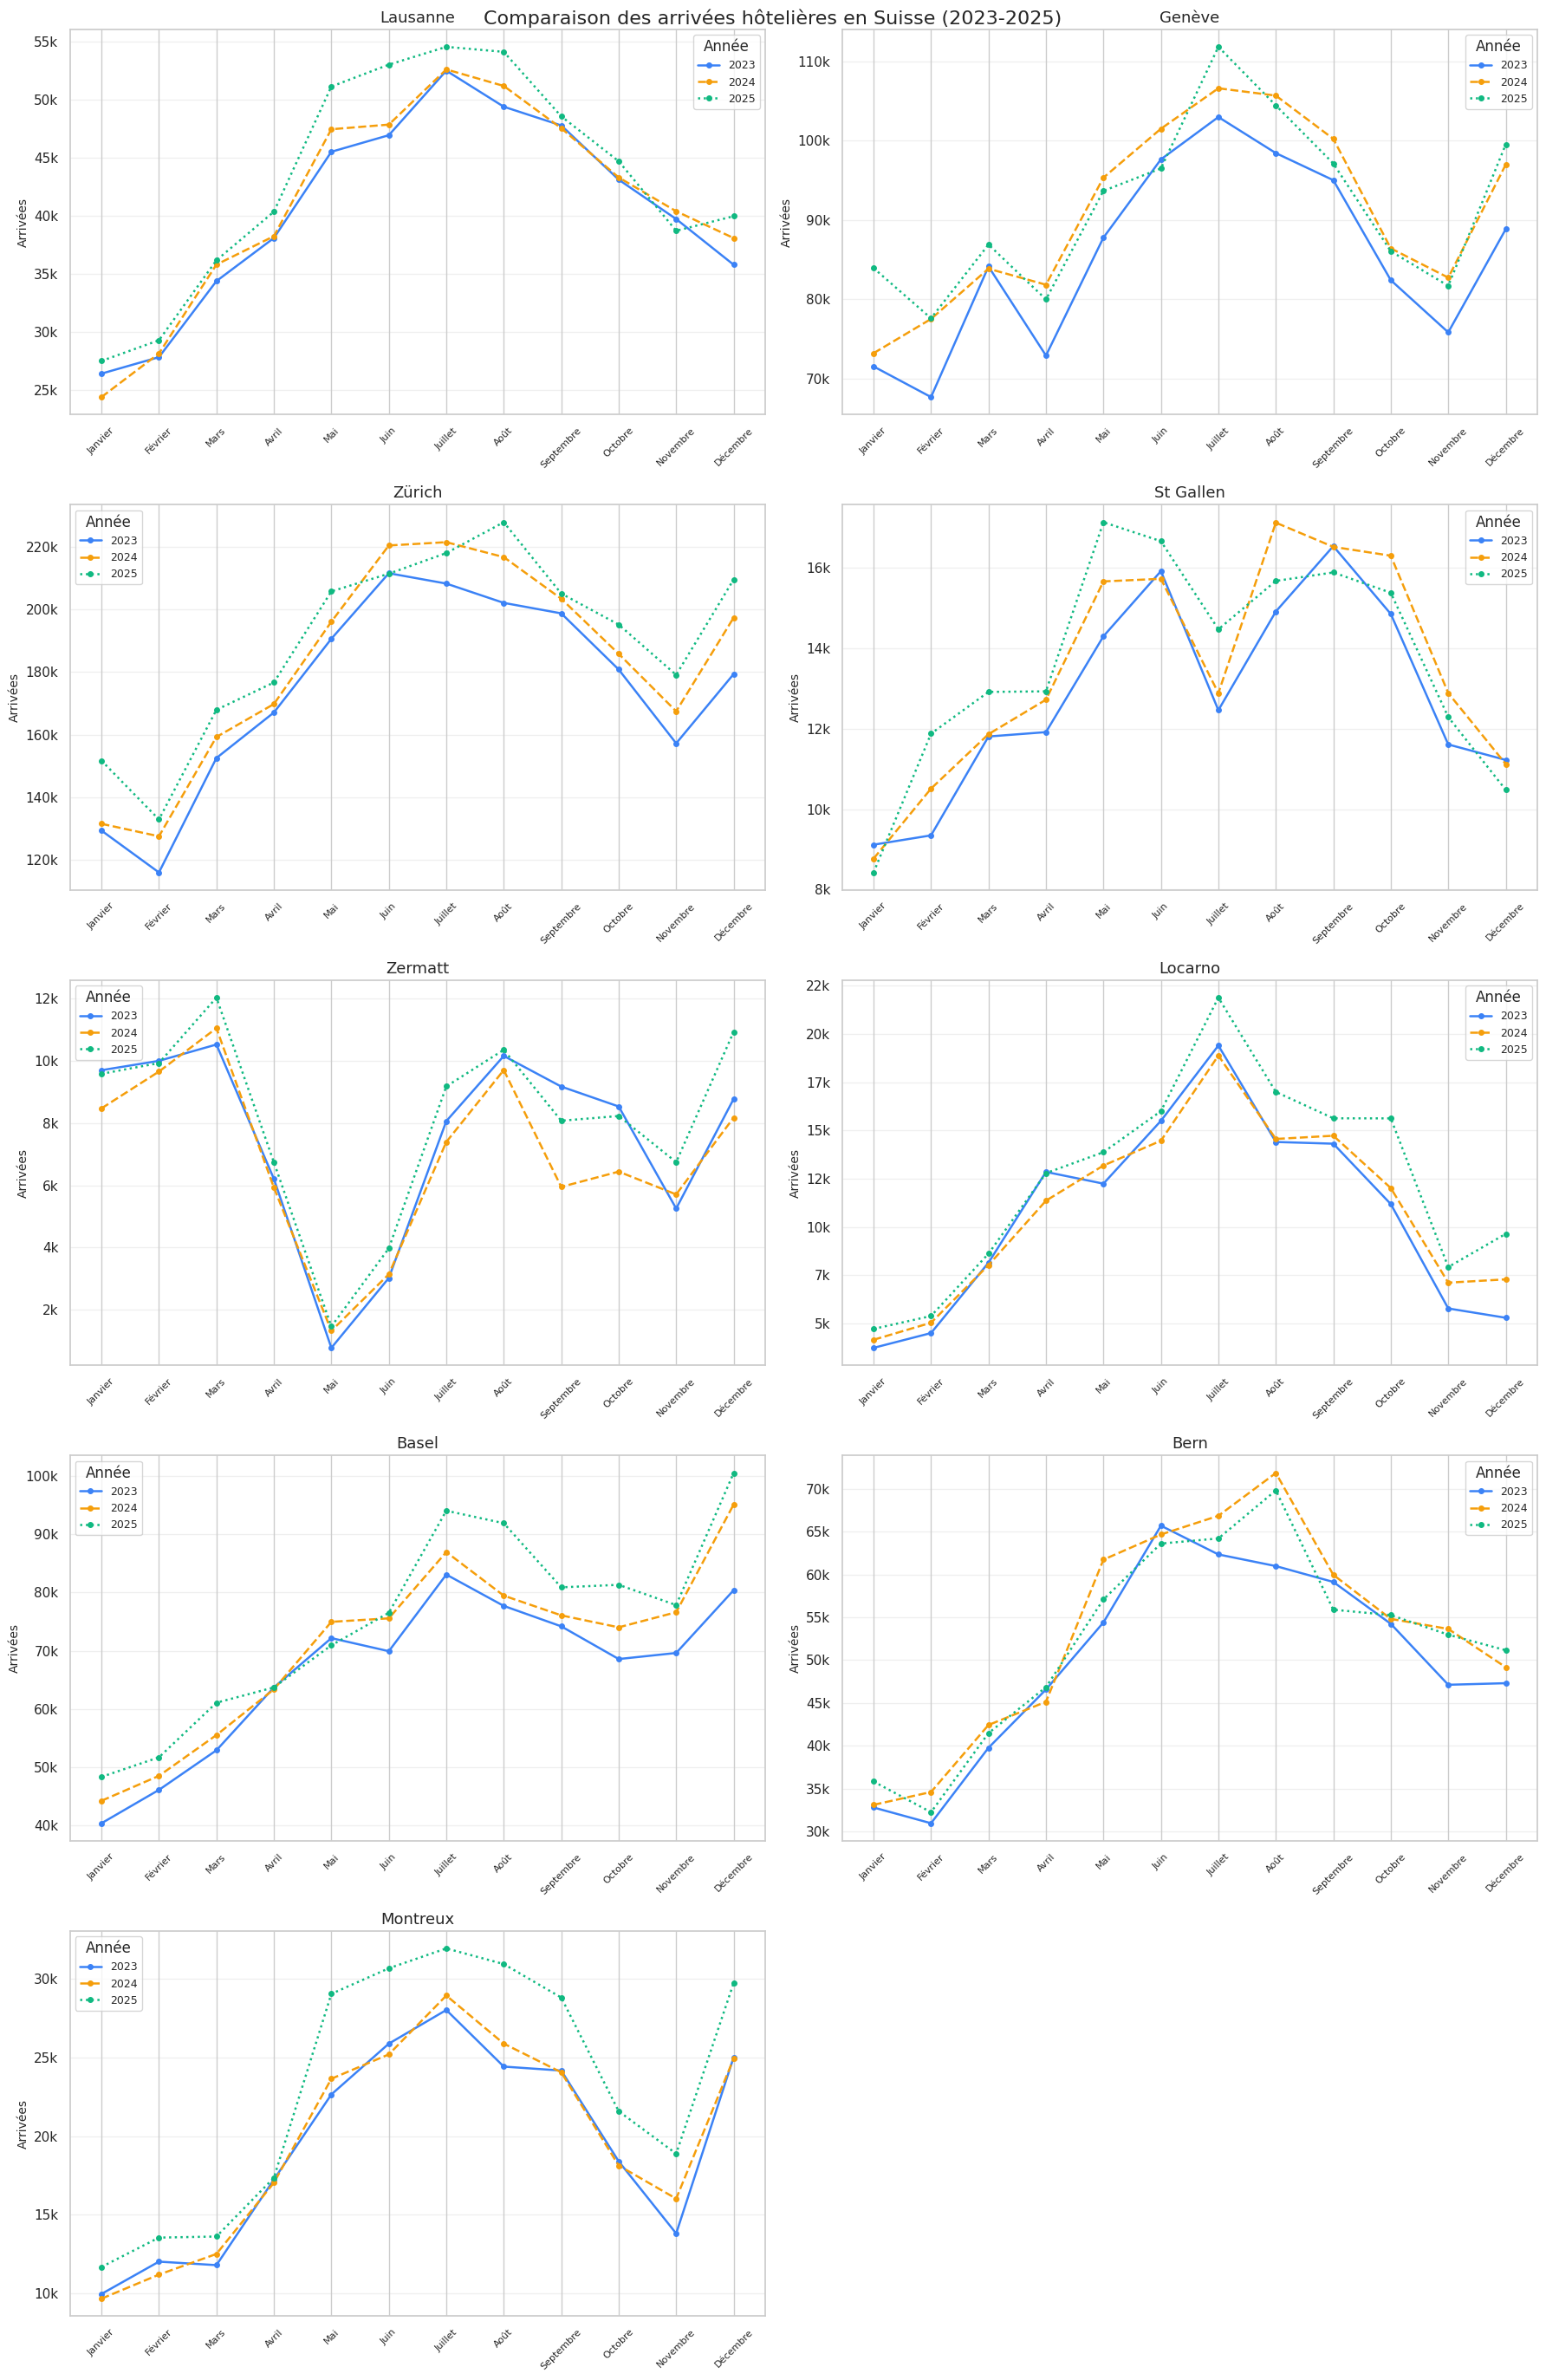

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

villes_cibles = [
    "Lausanne", "Genève", "Zürich", "St Gallen",
    "Zermatt", "Locarno", "Basel", "Bern", "Montreux"
]

annees_cibles = [2023, 2024, 2025]

ordre_mois = [
    "Janvier","Février","Mars","Avril","Mai","Juin",
    "Juillet","Août","Septembre","Octobre","Novembre","Décembre"
]

# filtrage
df_comp = df_tidy[
    (df_tidy["Pays"] == "Pays de provenance - total") &
    (df_tidy["Commune_nom"].isin(villes_cibles)) &
    (df_tidy["Année"].isin(annees_cibles)) &
    (df_tidy["Mois"] != "Total de l'année")
].copy()

# conversions
df_comp["Mois"] = pd.Categorical(
    df_comp["Mois"],
    categories=ordre_mois,
    ordered=True
)

df_comp["Année"] = pd.to_numeric(df_comp["Année"])

df_comp["Arrivées"] = pd.to_numeric(
    df_comp["Arrivées"],
    errors="coerce"
)

# styles
couleurs = {
    2023: "#3b82f6",
    2024: "#f59e0b",
    2025: "#10b981"
}

styles = {
    2023: "-",
    2024: "--",
    2025: ":"
}

# ===== FIGURE =====

fig, axes = plt.subplots(5, 2, figsize=(18, 28))
axes = axes.flatten()

for i, ville in enumerate(villes_cibles):

    ax = axes[i]

    df_ville = df_comp[
        df_comp["Commune_nom"] == ville
    ]

    for annee in annees_cibles:

        df_an = df_ville[
            df_ville["Année"] == annee
        ].sort_values("Mois")

        if df_an.empty:
            print(f"⚠️ Aucune donnée : {ville} / {annee}")
            continue

        ax.plot(
            df_an["Mois"],
            df_an["Arrivées"],
            label=str(annee),
            color=couleurs[annee],
            linestyle=styles[annee],
            marker="o",
            markersize=4,
            linewidth=1.8
        )

    ax.set_title(ville, fontsize=13)

    ax.set_ylabel("Arrivées", fontsize=10)

    ax.tick_params(
        axis="x",
        rotation=45,
        labelsize=8
    )

    ax.yaxis.set_major_formatter(
        mticker.FuncFormatter(
            lambda x, _: f"{int(x/1000)}k"
            if x >= 1000 else str(int(x))
        )
    )

    ax.legend(title="Année", fontsize=9)

    ax.grid(axis="y", alpha=0.3)

# supprimer le graphique vide
for j in range(len(villes_cibles), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Comparaison des arrivées hôtelières en Suisse (2023-2025)",
    fontsize=16
)

plt.tight_layout()

plt.show()

**Market share**

In [ ]:
import requests
import pandas as pd
from io import StringIO

url = "https://www.pxweb.bfs.admin.ch/api/v1/fr/px-x-1003020000_101/px-x-1003020000_101.px"

data = {
    "query": [
        {
            "code": "Jahr",
            "selection": {
                "filter": "item",
                "values": ["2023", "2024", "2025"]
            }
        },
        {
            "code": "Gemeinde",
            "selection": {
                "filter": "all",
                "values": ["*"]
            }
        }
    ],
    "response": {
        "format": "csv"
    }
}

# requête API
r = requests.post(url, json=data, timeout=120)

print(r.status_code)

# lecture CSV
df = pd.read_csv(StringIO(r.text))

# conversion numérique
df["Arrivées"] = pd.to_numeric(df["Arrivées"], errors="coerce")
df["Nuitées"] = pd.to_numeric(df["Nuitées"], errors="coerce")

# total suisse annuel
df_all_annuel = (
    df.groupby("Année")[["Arrivées", "Nuitées"]]
      .sum()
      .reset_index()
)

print(df_all_annuel)

200
   Année    Arrivées     Nuitées
0   2023  16462926.0  33316537.0
1   2024  17084104.0  34281628.0
2   2025  17592547.0  35201445.0


In [ ]:
df_market_share = ...

    Année Commune_nom  Arrivées_ville  Arrivées_suisse  Market_share
0  2023.0       Basel        798666.0       16462926.0      4.851300
1  2023.0        Bern        601276.0       16462926.0      3.652303
2  2023.0      Genève       1025412.0       16462926.0      6.228613
3  2023.0    Lausanne        487583.0       16462926.0      2.961703
4  2023.0     Locarno        127309.0       16462926.0      0.773307


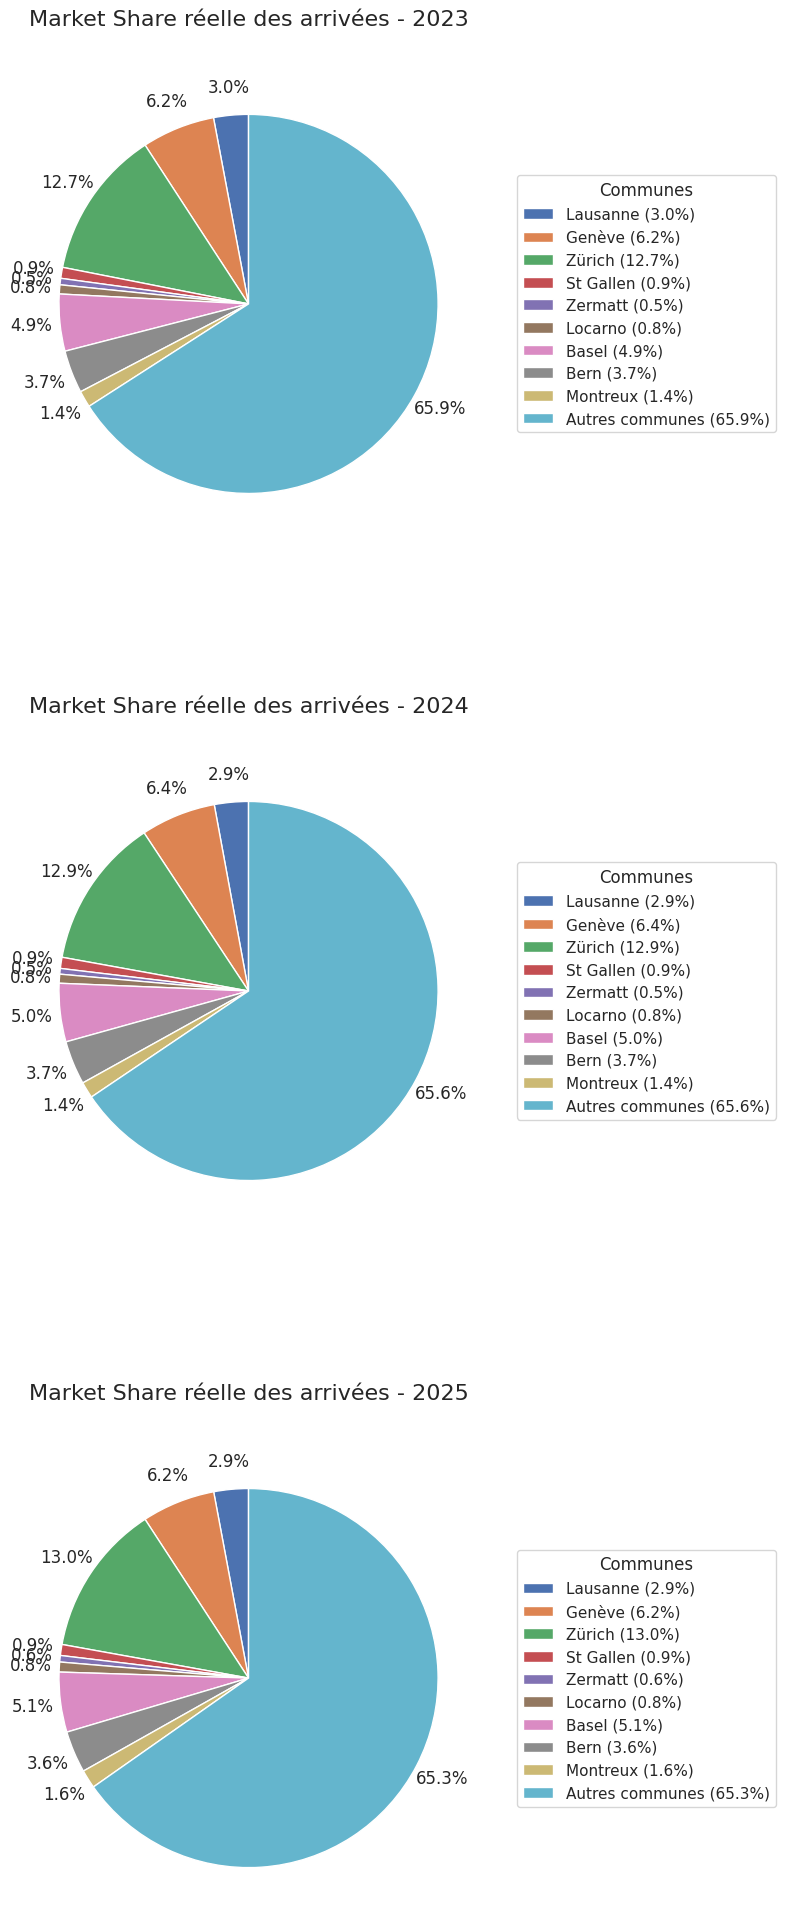

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# villes étudiées
villes_cibles = [
    "Lausanne", "Genève", "Zürich", "St Gallen",
    "Zermatt", "Locarno", "Basel", "Bern", "Montreux"
]

annees_cibles = [2023, 2024, 2025]

# ===== FILTRAGE =====

df_market_share_arrivees = df_tidy[
    (df_tidy["Pays"] == "Pays de provenance - total") &
    (df_tidy["Commune_nom"].isin(villes_cibles)) &
    (df_tidy["Année"].isin(annees_cibles)) &
    (df_tidy["Mois"] == "Total de l'année")
].copy()

# conversions numériques
df_market_share_arrivees["Arrivées"] = pd.to_numeric(
    df_market_share_arrivees["Arrivées"],
    errors="coerce"
)

df_market_share_arrivees["Année"] = pd.to_numeric(
    df_market_share_arrivees["Année"]
)

# ===== TOTAL ARRIVÉES PAR VILLE =====

df_market_share_arrivees = (
    df_market_share_arrivees.groupby(
        ["Année", "Commune_nom"]
    )["Arrivées"]
    .sum()
    .reset_index()
)

# ===== MERGE TOTAL SUISSE =====

df_market_share_arrivees = df_market_share_arrivees.merge(
    df_all_annuel[["Année", "Arrivées"]],
    on="Année",
    suffixes=("_ville", "_suisse")
)

# ===== MARKET SHARE ARRIVÉES =====

df_market_share_arrivees["Market_share"] = (
    df_market_share_arrivees["Arrivées_ville"] /
    df_market_share_arrivees["Arrivées_suisse"]
) * 100

print(df_market_share_arrivees.head())

# ===== PIE CHARTS AMÉLIORÉS =====

fig, axes = plt.subplots(3, 1, figsize=(12, 24))

for i, annee in enumerate(annees_cibles):

    df_an = df_market_share_arrivees[
        df_market_share_arrivees["Année"] == annee
    ].copy()

    # ordre forcé
    ordre_villes = [
        "Lausanne", "Genève", "Zürich", "St Gallen",
        "Zermatt", "Locarno", "Basel", "Bern", "Montreux"
    ]

    df_an["Commune_nom"] = pd.Categorical(
        df_an["Commune_nom"],
        categories=ordre_villes,
        ordered=True
    )

    df_an = df_an.sort_values("Commune_nom")

    # ajout autres communes
    reste = 100 - df_an["Market_share"].sum()

    labels = list(df_an["Commune_nom"]) + ["Autres communes"]
    values = list(df_an["Market_share"]) + [reste]

    # pie chart
    wedges, texts, autotexts = axes[i].pie(
        values,
        labels=None,
        autopct='%1.1f%%',
        startangle=90,
        pctdistance=1.15
    )

    axes[i].set_title(
        f"Market Share réelle des arrivées - {annee}",
        fontsize=16,
        pad=30
    )

    # légende
    legend_labels = [
        f"{label} ({value:.1f}%)"
        for label, value in zip(labels, values)
    ]

    axes[i].legend(
        wedges,
        legend_labels,
        title="Communes",
        loc="center left",
        bbox_to_anchor=(1.05, 0.5),
        fontsize=11
    )

plt.subplots_adjust(hspace=0.45)

plt.show()

Rebolote mais analyse des nuitée en market share

    Année Commune_nom  Nuitées_ville  Nuitées_suisse  Market_share
0  2023.0       Basel      1463684.0      33316537.0      4.393266
1  2023.0        Bern      1044046.0      33316537.0      3.133717
2  2023.0      Genève      2252671.0      33316537.0      6.761420
3  2023.0    Lausanne       930443.0      33316537.0      2.792736
4  2023.0     Locarno       275214.0      33316537.0      0.826058


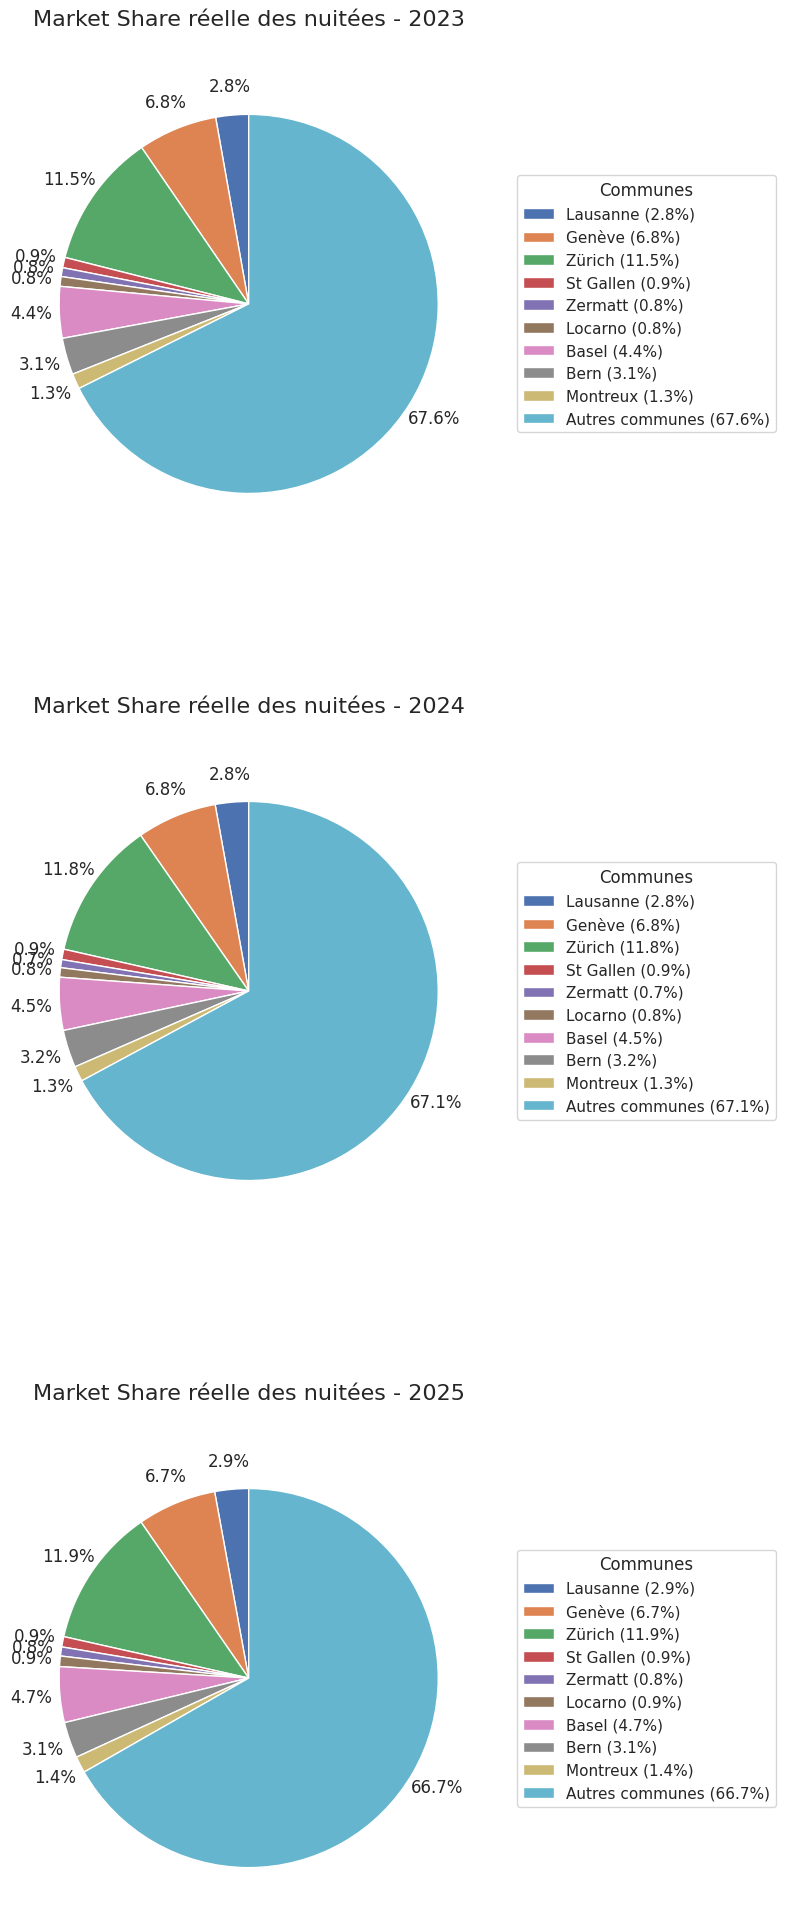

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# villes étudiées
villes_cibles = [
    "Lausanne", "Genève", "Zürich", "St Gallen",
    "Zermatt", "Locarno", "Basel", "Bern", "Montreux"
]

annees_cibles = [2023, 2024, 2025]

# ===== FILTRAGE =====

df_market_share_nuitees = df_tidy[
    (df_tidy["Pays"] == "Pays de provenance - total") &
    (df_tidy["Commune_nom"].isin(villes_cibles)) &
    (df_tidy["Année"].isin(annees_cibles)) &
    (df_tidy["Mois"] == "Total de l'année")
].copy()

# conversions numériques
df_market_share_nuitees["Nuitées"] = pd.to_numeric(
    df_market_share_nuitees["Nuitées"],
    errors="coerce"
)

df_market_share_nuitees["Année"] = pd.to_numeric(
    df_market_share_nuitees["Année"]
)

# ===== TOTAL NUITÉES PAR VILLE =====

df_market_share_nuitees = (
    df_market_share_nuitees.groupby(
        ["Année", "Commune_nom"]
    )["Nuitées"]
    .sum()
    .reset_index()
)

# ===== MERGE TOTAL SUISSE =====

df_market_share_nuitees = df_market_share_nuitees.merge(
    df_all_annuel[["Année", "Nuitées"]],
    on="Année",
    suffixes=("_ville", "_suisse")
)

# ===== MARKET SHARE NUITÉES =====

df_market_share_nuitees["Market_share"] = (
    df_market_share_nuitees["Nuitées_ville"] /
    df_market_share_nuitees["Nuitées_suisse"]
) * 100

print(df_market_share_nuitees.head())

# ===== PIE CHARTS =====

fig, axes = plt.subplots(3, 1, figsize=(12, 24))

for i, annee in enumerate(annees_cibles):

    df_an = df_market_share_nuitees[
        df_market_share_nuitees["Année"] == annee
    ].copy()

    # ordre fixe
    ordre_villes = [
        "Lausanne", "Genève", "Zürich", "St Gallen",
        "Zermatt", "Locarno", "Basel", "Bern", "Montreux"
    ]

    df_an["Commune_nom"] = pd.Categorical(
        df_an["Commune_nom"],
        categories=ordre_villes,
        ordered=True
    )

    df_an = df_an.sort_values("Commune_nom")

    # autres communes
    reste = 100 - df_an["Market_share"].sum()

    labels = list(df_an["Commune_nom"]) + ["Autres communes"]
    values = list(df_an["Market_share"]) + [reste]

    # pie chart
    wedges, texts, autotexts = axes[i].pie(
        values,
        labels=None,
        autopct='%1.1f%%',
        startangle=90,
        pctdistance=1.15
    )

    axes[i].set_title(
        f"Market Share réelle des nuitées - {annee}",
        fontsize=16,
        pad=30
    )

    # légende
    legend_labels = [
        f"{label} ({value:.1f}%)"
        for label, value in zip(labels, values)
    ]

    axes[i].legend(
        wedges,
        legend_labels,
        title="Communes",
        loc="center left",
        bbox_to_anchor=(1.05, 0.5),
        fontsize=11
    )

# espacement
plt.subplots_adjust(hspace=0.45)

plt.show()

**Analyse hors top 10**

In [ ]:
# ============================================================
# FILTRAGE + NETTOYAGE + MAPPING MOIS
# ============================================================

df_clean = lausanne_df.copy()

df_clean = df_clean[
    (df_clean["Commune_nom"] == "Lausanne") &
    (df_clean["Année"].isin([
        2013,2014,2015,2016,2017,
        2018,2019,2023,2024,2025
    ])) &
    (df_clean["Mois"] != "Total de l'année")  # ← intégré ici, plus de doublon
]

# Conversion numérique
df_clean["Nuitées"] = pd.to_numeric(
    df_clean["Nuitées"].astype(str)
    .str.replace("'", "", regex=False)
    .str.replace(" ", "", regex=False),
    errors="coerce"
)
df_clean["Arrivées"] = pd.to_numeric(
    df_clean["Arrivées"].astype(str)
    .str.replace("'", "", regex=False)
    .str.replace(" ", "", regex=False),
    errors="coerce"
)

# Nettoyage
df_clean = df_clean.dropna(subset=["Nuitées", "Arrivées"])
df_clean = df_clean[(df_clean["Nuitées"] >= 0) & (df_clean["Arrivées"] > 0)]
df_clean = df_clean[~df_clean["Pays"].isin(["Total", "Autres", "Autres pays", "Inconnu"])]

# Mapping mois → numérique
month_map = {
    "Janvier": 1, "Février": 2, "Mars": 3,
    "Avril": 4, "Mai": 5, "Juin": 6,
    "Juillet": 7, "Août": 8, "Septembre": 9,
    "Octobre": 10, "Novembre": 11, "Décembre": 12
}
df_clean["Mois_num"] = df_clean["Mois"].map(month_map)

print(df_clean.shape)
print(df_clean.columns.tolist())

(8724, 9)
['Année', 'Mois', 'Commune', 'Commune_nom', 'Pays', 'Arrivées', 'Nuitées', 'Request', 'Mois_num']


Cette étape consiste à transformer les données touristiques mensuelles brutes en une table de profils marchés agrégés par pays afin d’analyser le comportement touristique de chaque marché émetteur. À partir des données détaillées de Lausanne (df_clean), on regroupe les observations par pays (groupby("Pays")) puis on calcule des indicateurs stratégiques comme le nombre total de nuitées (total_nights), le nombre total d’arrivées (total_arrivals) et la durée moyenne de séjour (ALS = nuitées / arrivées). La logique statistique derrière cette transformation est de passer d’une analyse opérationnelle (ligne par ligne, mois par mois) à une analyse stratégique où chaque pays devient une unité d’analyse comparable. Cela permet ensuite d’identifier des profils de marchés, mesurer leur potentiel touristique et appliquer des méthodes de scoring ou de clustering pour détecter les marchés long-courriers les plus pertinents pour réduire la saisonnalité touristique de Lausanne.

In [ ]:
# ============================================================
# DÉFINITION DES SAISONS (numéros de mois)
# ============================================================
low_season  = [1, 2, 3, 11, 12]      # Jan, Fév, Mar, Nov, Déc
mid_season  = [4, 5, 10]             # Avr, Mai, Oct
high_season = [6, 7, 8, 9]           # Juin, Juil, Août, Sep

In [ ]:
import numpy as np

# ============================================================
# SAISONS
# ============================================================
low_season  = [1, 2, 3, 11, 12]
mid_season  = [4, 5, 10]
high_season = [6, 7, 8, 9]

# ============================================================
# CONSTRUCTION DF_FINAL PROPRE
# ============================================================
df_Final = (
    df_clean
    .groupby("Pays")
    .agg(
        total_nights=("Nuitées", "sum"),
        total_arrivals=("Arrivées", "sum")
    )
    .reset_index()   # ← Pays devient colonne dès le départ
)

df_Final["Pays"] = df_Final["Pays"].astype(str).str.strip()
df_Final["ALS"]  = df_Final["total_nights"] / df_Final["total_arrivals"]

# ============================================================
# RATIOS SAISONNIERS
# ============================================================
def season_ratio(df, months):
    return (
        df[df["Mois_num"].isin(months)]
        .groupby("Pays")["Nuitées"]
        .sum()
        .reset_index()
        .rename(columns={"Nuitées": "season_nights"})
    )

total = df_Final[["Pays", "total_nights"]]

for col, months in [
    ("low_season_ratio",  low_season),
    ("mid_season_ratio",  mid_season),
    ("high_season_ratio", high_season),
]:
    temp = season_ratio(df_clean, months)
    temp["Pays"] = temp["Pays"].astype(str).str.strip()
    df_Final = df_Final.merge(temp, on="Pays", how="left")
    df_Final[col] = df_Final["season_nights"] / df_Final["total_nights"]
    df_Final = df_Final.drop(columns=["season_nights"])

# ============================================================
# CAGR PAR PAYS
# ============================================================
yearly = (
    df_clean
    .groupby(["Pays", "Année"])["Nuitées"]
    .sum()
    .reset_index()
)
yearly["Pays"] = yearly["Pays"].astype(str).str.strip()

growth_list = []
for country in yearly["Pays"].unique():
    temp = yearly[yearly["Pays"] == country].sort_values("Année")
    first_value = temp.iloc[0]["Nuitées"]
    last_value  = temp.iloc[-1]["Nuitées"]
    n_years     = temp.iloc[-1]["Année"] - temp.iloc[0]["Année"]

    if first_value > 0 and n_years > 0:
        cagr = ((last_value / first_value) ** (1 / n_years)) - 1
    else:
        cagr = np.nan

    growth_list.append([country, cagr])

growth_df = pd.DataFrame(growth_list, columns=["Pays", "growth"])
growth_df["Pays"] = growth_df["Pays"].astype(str).str.strip()

# ============================================================
# MERGE GROWTH
# ============================================================
df_Final = df_Final.merge(growth_df, on="Pays", how="left")

# ============================================================
# VÉRIFICATION
# ============================================================
print(df_Final.columns.tolist())
print(df_Final[df_Final["Pays"] == "Russie"][["Pays", "growth"]])
df_Final.head()

['Pays', 'total_nights', 'total_arrivals', 'ALS', 'low_season_ratio', 'mid_season_ratio', 'high_season_ratio', 'growth']
      Pays    growth
58  Russie -0.107491


,Pays,total_nights,total_arrivals,ALS,low_season_ratio,mid_season_ratio,high_season_ratio,growth
0,Afrique du Sud,16581.0,4689.0,3.536148,0.344249,0.236536,0.419215,-0.008337
1,Allemagne,374205.0,182968.0,2.045194,0.308823,0.257241,0.433936,0.024230
2,Arabie saoudite,100936.0,26840.0,3.760656,0.179688,0.172624,0.647688,0.075456
3,Argentine,16203.0,5322.0,3.044532,0.351170,0.255447,0.393384,-0.028640
4,Australie,61922.0,24583.0,2.518895,0.305013,0.223345,0.471642,0.002590


Nous avons transformé les données mensuelles de fréquentation hôtelière de Lausanne en une base analytique structurée permettant d’étudier les comportements des marchés touristiques internationaux. Après avoir nettoyé les données (suppression des valeurs agrégées, conversion numérique et harmonisation des mois), nous avons construit un dataframe agrégé par pays (df_Final) contenant des indicateurs stratégiques tels que le volume total de nuitées, le nombre total d’arrivées et la durée moyenne de séjour (ALS). Nous avons ensuite introduit une dimension saisonnière en calculant la part des nuitées générées en basse, moyenne et haute saison pour chaque marché. Cette approche permet désormais d’identifier les pays présentant un potentiel intéressant pour réduire la saisonnalité touristique lausannoise, notamment les marchés long-courriers dont les habitudes de voyage sont moins dépendantes de l’été européen.f

In [ ]:
# ============================================================
# STABILITÉ SAISONNIÈRE (CV)
# ============================================================

monthly_avg = (
    df_clean
    .groupby(["Pays", "Mois_num"])["Nuitées"]
    .mean()
    .reset_index()
)

cv_df = (
    monthly_avg
    .groupby("Pays")["Nuitées"]
    .agg(
        lambda x: x.std() / x.mean()
    )
    .reset_index()
)

cv_df.columns = [
    "Pays",
    "seasonality_cv"
]

# ============================================================
# MERGE PROPRE
# ============================================================

if "seasonality_cv" in df_Final.columns:
    df_Final = df_Final.drop(
        columns=["seasonality_cv"]
    )

df_Final = df_Final.merge(
    cv_df,
    on="Pays",
    how="left"
)

# ============================================================
# CHECK
# ============================================================

print(df_Final.columns)

df_Final.head()

Index(['Pays', 'total_nights', 'total_arrivals', 'ALS', 'low_season_ratio',
       'mid_season_ratio', 'high_season_ratio', 'growth', 'seasonality_cv'],
      dtype='object')


,Pays,total_nights,total_arrivals,ALS,low_season_ratio,mid_season_ratio,high_season_ratio,growth,seasonality_cv
0,Afrique du Sud,16581.0,4689.0,3.536148,0.344249,0.236536,0.419215,-0.008337,0.262765
1,Allemagne,374205.0,182968.0,2.045194,0.308823,0.257241,0.433936,0.024230,0.286030
2,Arabie saoudite,100936.0,26840.0,3.760656,0.179688,0.172624,0.647688,0.075456,0.870070
3,Argentine,16203.0,5322.0,3.044532,0.351170,0.255447,0.393384,-0.028640,0.229825
4,Australie,61922.0,24583.0,2.518895,0.305013,0.223345,0.471642,0.002590,0.341205


In [ ]:
import numpy as np

trouver nos target:

In [ ]:
df_Target = df_Final[
    ~df_Final["Pays"].str.contains("Autres")
]
top_markets = [
    "Suisse",
    "France",
    "États-Unis",
    "Allemagne",
    "Royaume-Uni",
    "Italie",
    "Chine",
    "Espagne",
    "Belgique",
    "Pays-Bas"
]

df_Target = df_Target[
    ~df_Target["Pays"].isin(top_markets)
]
df_Target = df_Target[
    df_Target["total_nights"] > 15000
]

In [ ]:
# ============================================================
# EXCLUSION EUROPE
# ============================================================

europe_countries = [

    "Albanie",
    "Allemagne",
    "Andorre",
    "Autriche",
    "Belgique",
    "Bosnie-Herzégovine",
    "Bulgarie",
    "Croatie",
    "Danemark",
    "Espagne",
    "Estonie",
    "Finlande",
    "France",
    "Grèce",
    "Hongrie",
    "Irlande",
    "Islande",
    "Italie",
    "Kosovo",
    "Lettonie",
    "Liechtenstein",
    "Lituanie",
    "Luxembourg",
    "Malte",
    "Moldavie",
    "Monténégro",
    "Norvège",
    "Pays-Bas",
    "Pologne",
    "Portugal",
    "Roumanie",
    "Royaume-Uni",
    "Serbie",
    "Slovaquie",
    "Slovénie",
    "Suède",
    "Suisse",
    "Tchéquie",
    "Ukraine"
]

df_Target = df_Target[
    ~df_Target["Pays"].isin(europe_countries)
]

df_Target = df_Target.sort_values(
    ["low_season_ratio"],
    ascending=False
)

df_Target.reset_index()[
    [
        "Pays",
        "total_nights",
        "ALS",
        "low_season_ratio",
        "growth",

    ]
].head(20)

,Pays,total_nights,ALS,low_season_ratio,growth
0,Égypte,16686.0,3.938164,0.414239,0.008862
1,Russie,110066.0,2.801517,0.382171,-0.107491
2,Turquie,38438.0,2.630938,0.366668,0.005869
3,Argentine,16203.0,3.044532,0.351170,-0.028640
4,Brésil,74709.0,2.769154,0.351029,0.001642
5,Afrique du Sud,16581.0,3.536148,0.344249,-0.008337
6,Indonésie,17260.0,2.543847,0.337717,0.022346
7,Pays de provenance - total,8883299.0,1.999579,0.337344,0.025202
8,Singapour,32069.0,2.748929,0.328729,0.031108
9,Mexique,23066.0,2.652484,0.306468,0.043452


In [ ]:
# ============================================================
# TRI PAR VOLUME TOTAL DE NUITÉES
# ============================================================

df_Target = df_Target.sort_values(
    "total_nights",
    ascending=False
)
df_Target = df_Target[
    df_Target["Pays"] != "Pays de provenance - total"
]

# ============================================================
# AFFICHAGE FINAL
# ============================================================

df_Target.reset_index()[
    [
        "Pays",
        "total_nights",
        "ALS",
        "low_season_ratio",
        "growth",

    ]
].head(20)

,Pays,total_nights,ALS,low_season_ratio,growth
0,Russie,110066.0,2.801517,0.382171,-0.107491
1,Arabie saoudite,100936.0,3.760656,0.179688,0.075456
2,Japon,96725.0,2.323277,0.263758,-0.037661
3,Canada,85310.0,2.574386,0.267929,0.018773
4,Émirats arabes unis,84397.0,3.753647,0.210754,0.026787
5,Brésil,74709.0,2.769154,0.351029,0.001642
6,Inde,69217.0,2.998094,0.259344,0.026113
7,Australie,61922.0,2.518895,0.305013,0.002590
8,Thaïlande,42227.0,1.594916,0.249959,-0.000704
9,Corée (Sud),41014.0,1.692695,0.259204,0.009074


toop target selon nuitée

In [ ]:
# ============================================================
# TOP 8 MARCHÉS PAR VOLUME DE NUITÉES
# ============================================================

top_nights = (

    df_Target

    # Retirer ligne totale
    [
        df_Target["Pays"] != "Pays de provenance - total"
    ]

    # Trier par volume
    .sort_values(
        "total_nights",
        ascending=False
    )

    # Top 8
    .head(8)

)

# ============================================================
# AFFICHAGE
# ============================================================

top_nights[
    [
        "Pays",
        "total_nights",
        "ALS",
        "low_season_ratio",
        "growth"
    ]
]

,Pays,total_nights,ALS,low_season_ratio,growth
58,Russie,110066.0,2.801517,0.382171,-0.107491
2,Arabie saoudite,100936.0,3.760656,0.179688,0.075456
38,Japon,96725.0,2.323277,0.263758,-0.037661
18,Canada,85310.0,2.574386,0.267929,0.018773
71,Émirats arabes unis,84397.0,3.753647,0.210754,0.026787
15,Brésil,74709.0,2.769154,0.351029,0.001642
32,Inde,69217.0,2.998094,0.259344,0.026113
4,Australie,61922.0,2.518895,0.305013,0.002590


top target selon ALS (premium)

In [ ]:
# ============================================================
# TOP 8 MARCHÉS PREMIUM (ALS)
# ============================================================

top_premium = (

    df_Target

    # Retirer ligne totale
    [
        df_Target["Pays"] != "Pays de provenance - total"
    ]

    # Éviter petits marchés artificiels
    [
        df_Target["total_nights"] > 15000
    ]

    # Trier par ALS
    .sort_values(
        "ALS",
        ascending=False
    )

    # Top 8
    .head(8)

)

# ============================================================
# AFFICHAGE
# ============================================================

top_premium[
    [
        "Pays",
        "ALS",
        "total_nights",
        "low_season_ratio",
        "growth"
    ]
]

,Pays,ALS,total_nights,low_season_ratio,growth
70,Égypte,3.938164,16686.0,0.414239,0.008862
39,Koweït,3.855970,27709.0,0.133350,0.028933
2,Arabie saoudite,3.760656,100936.0,0.179688,0.075456
71,Émirats arabes unis,3.753647,84397.0,0.210754,0.026787
55,Qatar,3.713703,20028.0,0.198372,0.056818
0,Afrique du Sud,3.536148,16581.0,0.344249,-0.008337
3,Argentine,3.044532,16203.0,0.351170,-0.028640
32,Inde,2.998094,69217.0,0.259344,0.026113


In [ ]:
# ============================================================
# TOP 8 MARCHÉS PREMIUM (low_season_ratio)
# ============================================================

top_premium = (

    df_Target

    # Retirer ligne totale
    [
        df_Target["Pays"] != "Pays de provenance - total"
    ]

    # Éviter petits marchés artificiels
    [
        df_Target["total_nights"] > 15000
    ]

    # Trier par ALS
    .sort_values(
        "low_season_ratio",
        ascending=False
    )

    # Top 8
    .head(8)

)

# ============================================================
# AFFICHAGE
# ============================================================

top_premium[
    [
        "Pays",
        "ALS",
        "total_nights",
        "low_season_ratio",
        "growth"
    ]
]

,Pays,ALS,total_nights,low_season_ratio,growth
70,Égypte,3.938164,16686.0,0.414239,0.008862
58,Russie,2.801517,110066.0,0.382171,-0.107491
68,Turquie,2.630938,38438.0,0.366668,0.005869
3,Argentine,3.044532,16203.0,0.351170,-0.028640
15,Brésil,2.769154,74709.0,0.351029,0.001642
0,Afrique du Sud,3.536148,16581.0,0.344249,-0.008337
33,Indonésie,2.543847,17260.0,0.337717,0.022346
60,Singapour,2.748929,32069.0,0.328729,0.031108


final target:
Moyen-Orient	Arabie saoudite, UAE, Qatar
Asie	Inde, Japon, Singapour
Amérique du Sud	Brésil, Argentine
Afrique	Afrique du Sud

Final target

In [ ]:
# ============================================================
# PAYS CIBLES FINAUX
# ============================================================

target_markets = [
    "Arabie saoudite",
    "Émirats arabes unis",
    "Qatar",
    "Inde",
    "Singapour",
    "Japon",
    "Brésil",
    "Argentine"
]

# ============================================================
# TABLEAU FINAL
# ============================================================

df_targets_final = (

    df_Target[
        df_Target["Pays"].isin(target_markets)
    ]

    .sort_values(
        "total_nights",
        ascending=False
    )

)

display(

    df_targets_final[
        [
            "Pays",
            "total_nights",
            "ALS",
            "low_season_ratio",
            "growth",

        ]
    ]

)

,Pays,total_nights,ALS,low_season_ratio,growth
2,Arabie saoudite,100936.0,3.760656,0.179688,0.075456
38,Japon,96725.0,2.323277,0.263758,-0.037661
71,Émirats arabes unis,84397.0,3.753647,0.210754,0.026787
15,Brésil,74709.0,2.769154,0.351029,0.001642
32,Inde,69217.0,2.998094,0.259344,0.026113
60,Singapour,32069.0,2.748929,0.328729,0.031108
55,Qatar,20028.0,3.713703,0.198372,0.056818
3,Argentine,16203.0,3.044532,0.351170,-0.028640


graphes targets:

/tmp/ipykernel_1330/3917756930.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lausanne_recent["Mois"] = pd.Categorical(


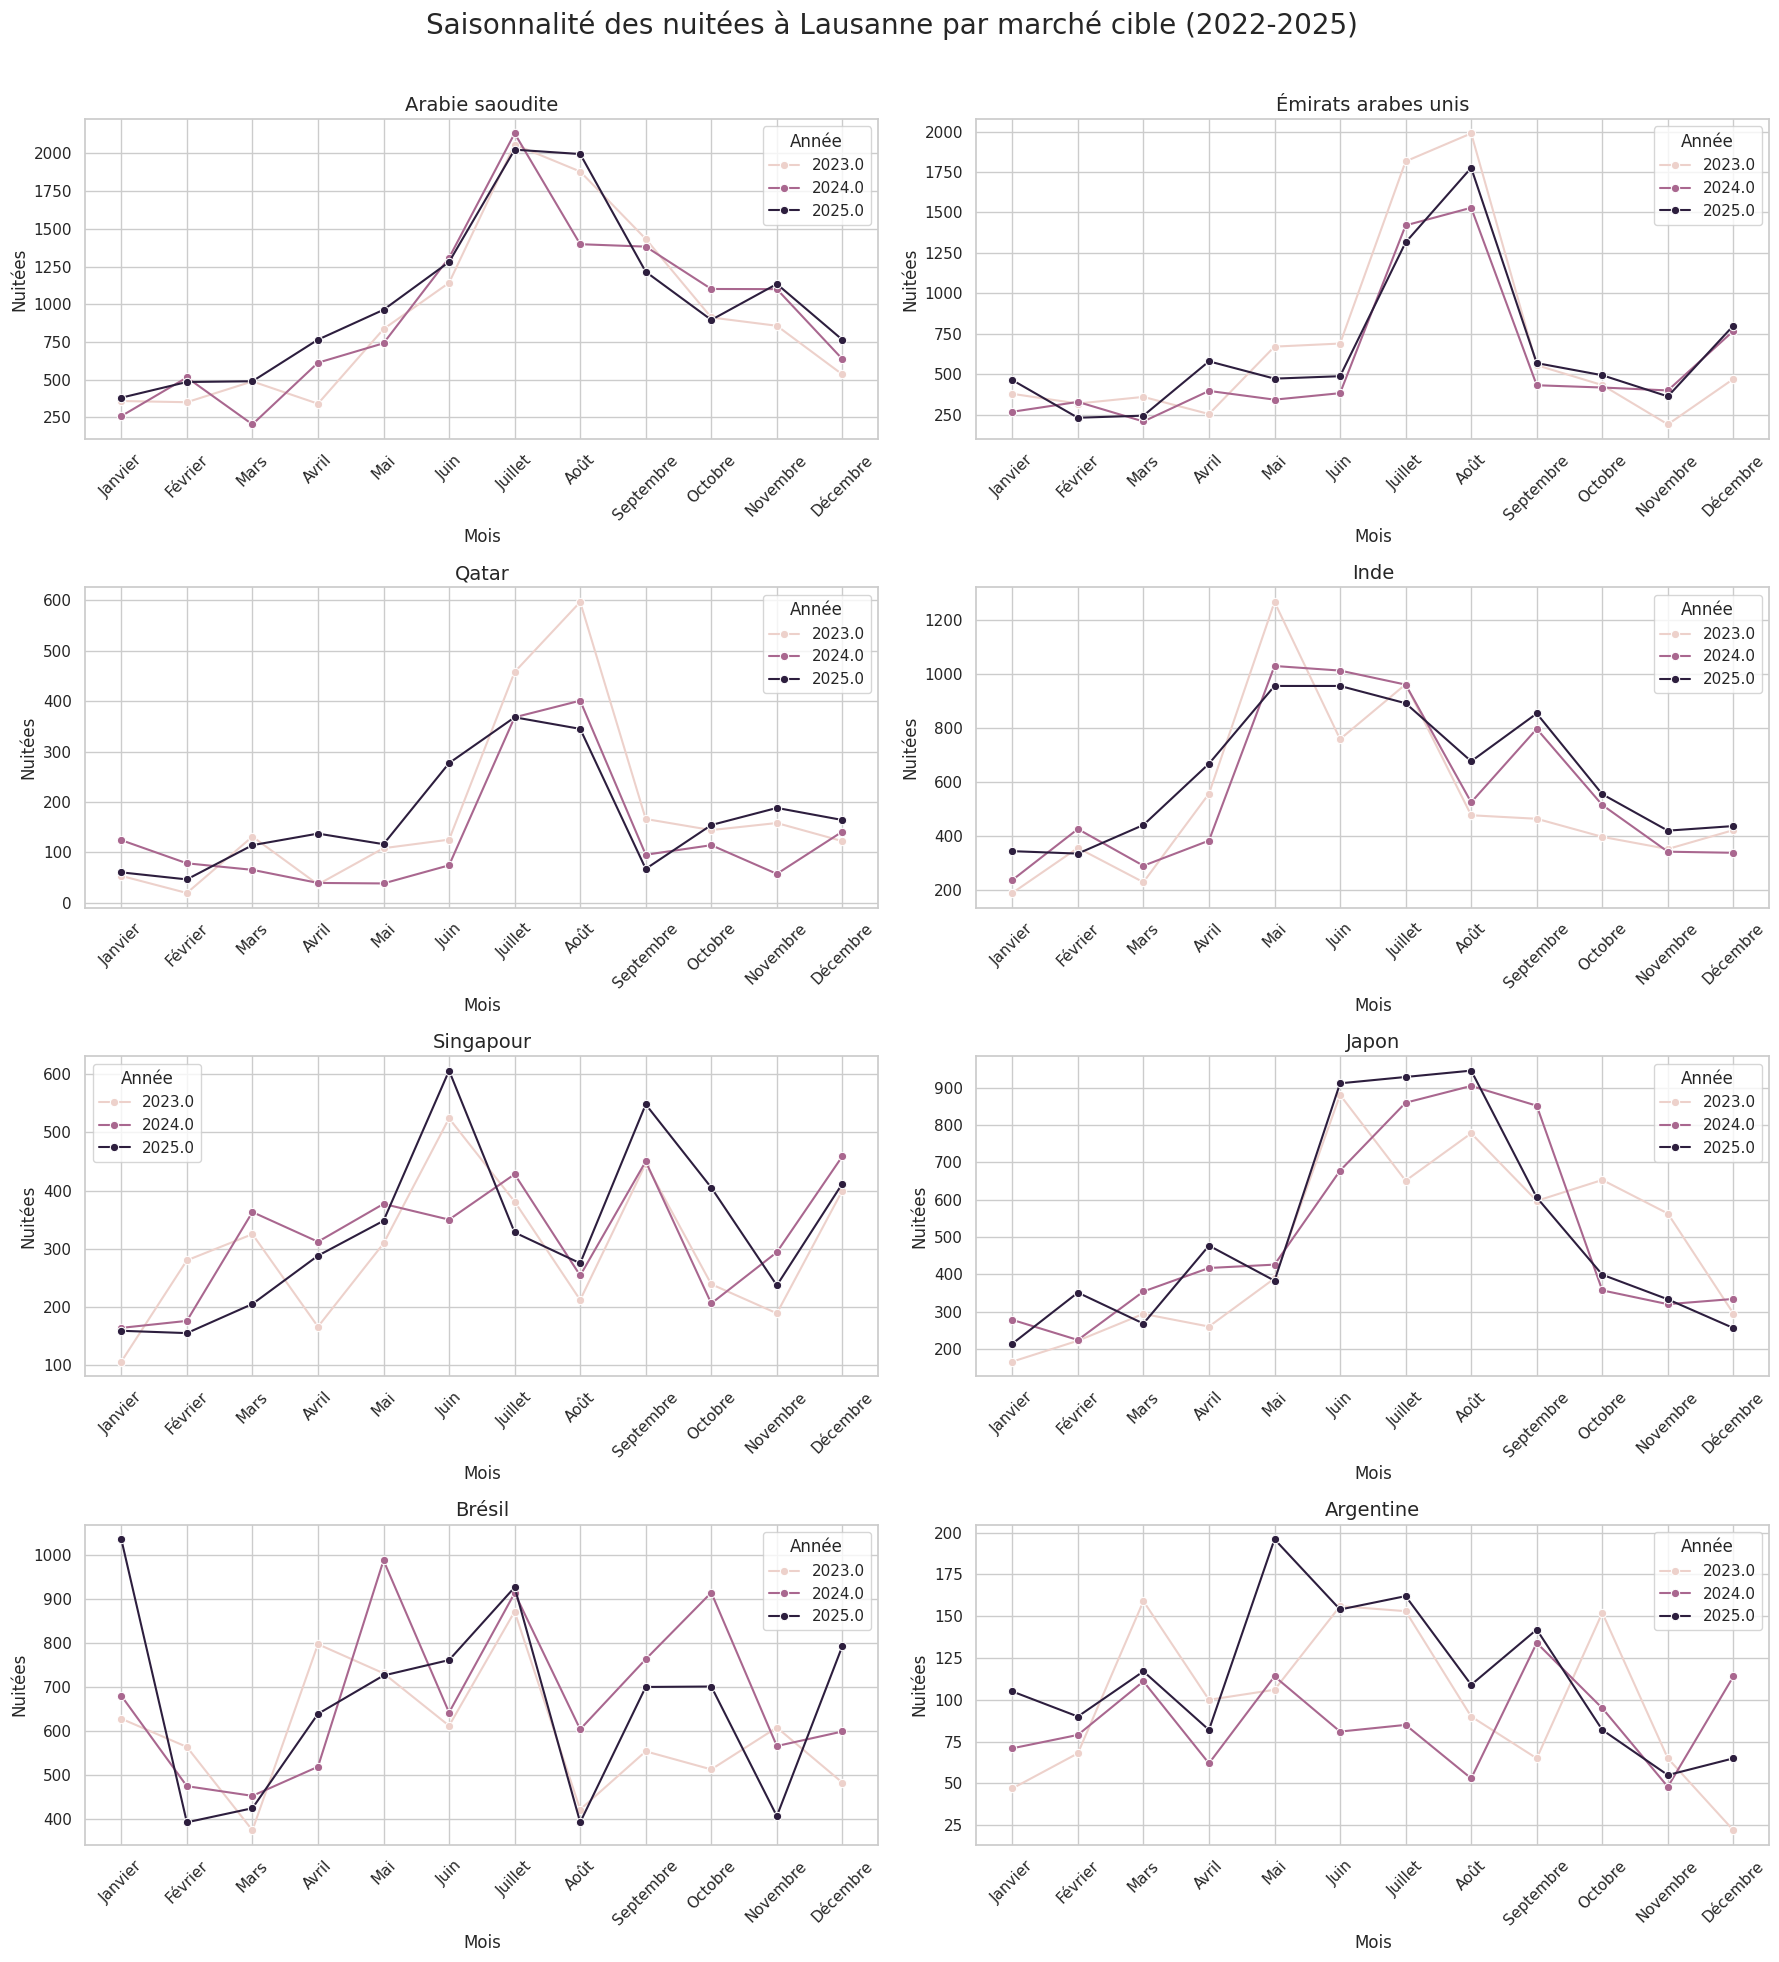

In [ ]:
# ============================================================
# GRAPHIQUE SAISONNALITÉ DES MARCHÉS CIBLES
# ============================================================



# ============================================================
# DONNÉES RÉCENTES
# ============================================================

lausanne_recent = df_clean[
    (df_clean["Pays"].isin(target_markets)) &
    (df_clean["Année"].isin([2022, 2023, 2024, 2025]))
]

# ============================================================
# ORDRE DES MOIS
# ============================================================

mois_ordre = [
    "Janvier",
    "Février",
    "Mars",
    "Avril",
    "Mai",
    "Juin",
    "Juillet",
    "Août",
    "Septembre",
    "Octobre",
    "Novembre",
    "Décembre"
]

lausanne_recent["Mois"] = pd.Categorical(
    lausanne_recent["Mois"],
    categories=mois_ordre,
    ordered=True
)

# ============================================================
# CRÉATION DES SOUS-GRAPHES
# ============================================================

fig, axes = plt.subplots(
    4,
    2,
    figsize=(18, 20)
)

axes = axes.flatten()

# ============================================================
# GRAPHE PAR PAYS
# ============================================================

for i, market in enumerate(target_markets):

    data_market = lausanne_recent[
        lausanne_recent["Pays"] == market
    ]

    sns.lineplot(
        data=data_market,
        x="Mois",
        y="Nuitées",
        hue="Année",
        marker="o",
        ax=axes[i]
    )

    axes[i].set_title(
        market,
        fontsize=14
    )

    axes[i].set_ylabel("Nuitées")
    axes[i].set_xlabel("Mois")

    axes[i].tick_params(
        axis="x",
        rotation=45
    )

# ============================================================
# TITRE GLOBAL
# ============================================================

plt.suptitle(
    "Saisonnalité des nuitées à Lausanne par marché cible (2022-2025)",
    fontsize=20
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

plt.show()

graphes top low season hors europe

/tmp/ipykernel_1330/3071347594.py:44: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lausanne_low["Mois"] = pd.Categorical(


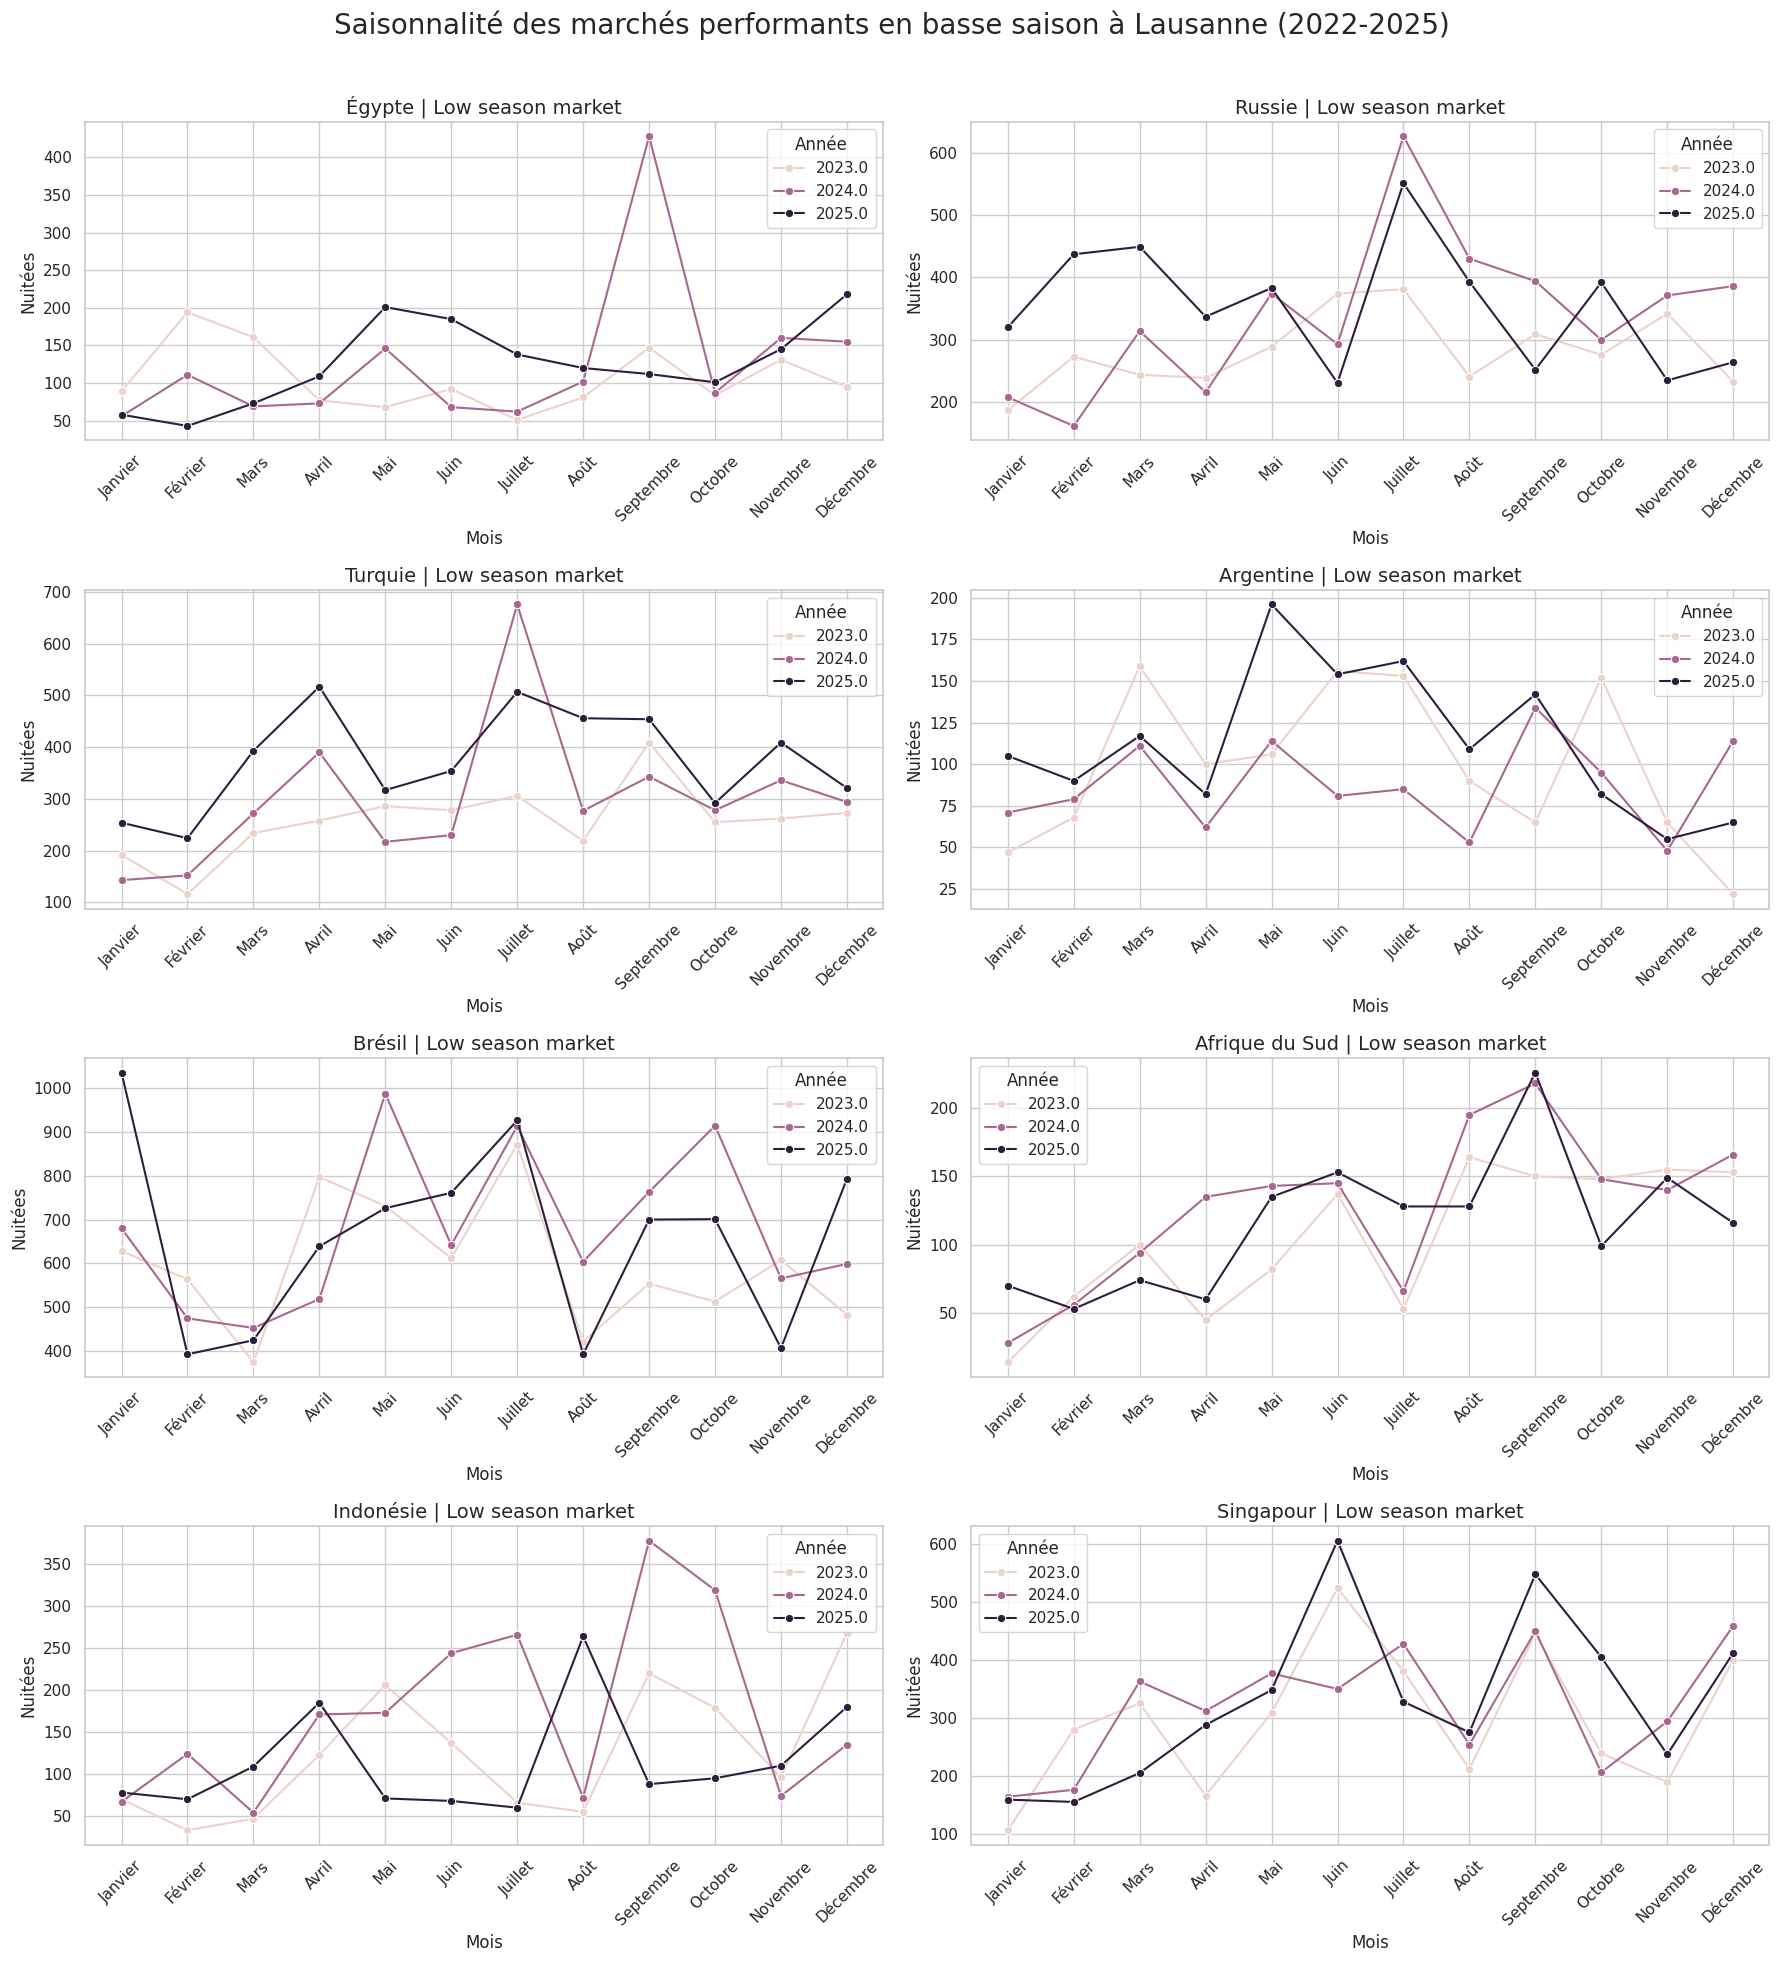

In [ ]:
# ============================================================
# MARCHÉS LOW SEASON
# ============================================================

low_season_markets = [
    "Égypte",
    "Russie",
    "Turquie",
    "Argentine",
    "Brésil",
    "Afrique du Sud",
    "Indonésie",
    "Singapour"
]

# ============================================================
# DONNÉES RÉCENTES
# ============================================================

lausanne_low = df_clean[
    (df_clean["Pays"].isin(low_season_markets)) &
    (df_clean["Année"].isin([2022, 2023, 2024, 2025]))
]

# ============================================================
# ORDRE DES MOIS
# ============================================================

mois_ordre = [
    "Janvier",
    "Février",
    "Mars",
    "Avril",
    "Mai",
    "Juin",
    "Juillet",
    "Août",
    "Septembre",
    "Octobre",
    "Novembre",
    "Décembre"
]

lausanne_low["Mois"] = pd.Categorical(
    lausanne_low["Mois"],
    categories=mois_ordre,
    ordered=True
)

# ============================================================
# CRÉATION DES GRAPHIQUES
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(
    4,
    2,
    figsize=(18, 20)
)

axes = axes.flatten()

# ============================================================
# GRAPHE PAR MARCHÉ
# ============================================================

for i, market in enumerate(low_season_markets):

    data_market = lausanne_low[
        lausanne_low["Pays"] == market
    ]

    sns.lineplot(
        data=data_market,
        x="Mois",
        y="Nuitées",
        hue="Année",
        marker="o",
        ax=axes[i]
    )

    axes[i].set_title(
        f"{market} | Low season market",
        fontsize=14
    )

    axes[i].set_ylabel("Nuitées")
    axes[i].set_xlabel("Mois")

    axes[i].tick_params(
        axis="x",
        rotation=45
    )

# ============================================================
# TITRE GLOBAL
# ============================================================

plt.suptitle(
    "Saisonnalité des marchés performants en basse saison à Lausanne (2022-2025)",
    fontsize=20
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

plt.show()

**Regression**

In [ ]:
# ============================================================
#  SETUP RÉGRESSION OLS
# Features brutes + région + matrice X
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.preprocessing import MinMaxScaler

# --- Volume total ---
total_nights_raw = (
    df_clean.groupby("Pays")["Nuitées"].sum()
    .rename("total_nights_raw")
)

total_arrivals_raw = (
    df_clean.groupby("Pays")["Arrivées"].sum()
    .rename("total_arrivals_raw")
)

# --- ALS brut (jours) ---
als_raw = (total_nights_raw / total_arrivals_raw).rename("ALS_raw")

# --- Ratios saisonniers bruts ---
low_season  = [1, 2, 3, 11, 12]
mid_season  = [4, 5, 10]
high_season = [6, 7, 8, 9]

low_nights_raw  = df_clean[df_clean["Mois_num"].isin(low_season)].groupby("Pays")["Nuitées"].sum()
mid_nights_raw  = df_clean[df_clean["Mois_num"].isin(mid_season)].groupby("Pays")["Nuitées"].sum()
high_nights_raw = df_clean[df_clean["Mois_num"].isin(high_season)].groupby("Pays")["Nuitées"].sum()

low_ratio_raw  = (low_nights_raw  / total_nights_raw).rename("low_season_ratio_raw")
mid_ratio_raw  = (mid_nights_raw  / total_nights_raw).rename("mid_season_ratio_raw")
high_ratio_raw = (high_nights_raw / total_nights_raw).rename("high_season_ratio_raw")

# --- CAGR brut ---
yearly = (
    df_clean.groupby(["Pays", "Année"])["Nuitées"]
    .sum().reset_index()
)

growth_list = []
for country in yearly["Pays"].unique():
    temp = yearly[yearly["Pays"] == country].sort_values("Année")
    first_year  = temp["Année"].min()
    last_year   = temp["Année"].max()
    first_value = temp[temp["Année"] == first_year]["Nuitées"].values[0]
    last_value  = temp[temp["Année"] == last_year]["Nuitées"].values[0]
    n_years = last_year - first_year
    if first_value > 0 and n_years > 0:
        cagr = (last_value / first_value) ** (1 / n_years) - 1
    else:
        cagr = np.nan
    growth_list.append([country, cagr])

growth_raw = (
    pd.DataFrame(growth_list, columns=["Pays", "growth_raw"])
    .set_index("Pays")["growth_raw"]
)

# --- CV saisonnier brut ---
monthly_avg = (
    df_clean.groupby(["Pays", "Mois_num"])["Nuitées"]
    .mean().reset_index()
)

cv_raw = (
    monthly_avg.groupby("Pays")["Nuitées"]
    .agg(lambda x: x.std() / x.mean())
    .rename("seasonality_cv_raw")
)

# --- Assemblage df_reg ---
df_reg = pd.concat([
    total_nights_raw,
    als_raw,
    low_ratio_raw,
    mid_ratio_raw,
    high_ratio_raw,
    growth_raw,
    cv_raw
], axis=1).reset_index()

df_reg.columns.name = None

# --- Mapping région ---
region_map = {
    # Moyen-Orient
    "Arabie saoudite": "Moyen-Orient",
    "Émirats arabes unis": "Moyen-Orient",
    "Qatar": "Moyen-Orient",
    "Koweït": "Moyen-Orient",
    "Bahreïn": "Moyen-Orient",
    "Oman": "Moyen-Orient",
    "Israël": "Moyen-Orient",
    "Liban": "Moyen-Orient",
    "Jordanie": "Moyen-Orient",
    "Iran": "Moyen-Orient",
    "Irak": "Moyen-Orient",
    "Syrie": "Moyen-Orient",
    "Turquie": "Moyen-Orient",
    # Asie-Pacifique
    "Inde": "Asie-Pacifique",
    "Japon": "Asie-Pacifique",
    "Singapour": "Asie-Pacifique",
    "Chine": "Asie-Pacifique",
    "Corée du Sud": "Asie-Pacifique",
    "Corée (Sud)": "Asie-Pacifique",
    "Taïwan": "Asie-Pacifique",
    "Taïwan (Taipei chinois)": "Asie-Pacifique",
    "Hong Kong": "Asie-Pacifique",
    "Thaïlande": "Asie-Pacifique",
    "Malaisie": "Asie-Pacifique",
    "Indonésie": "Asie-Pacifique",
    "Philippines": "Asie-Pacifique",
    "Vietnam": "Asie-Pacifique",
    "Pakistan": "Asie-Pacifique",
    "Bangladesh": "Asie-Pacifique",
    "Sri Lanka": "Asie-Pacifique",
    "Australie": "Asie-Pacifique",
    "Nouvelle-Zélande": "Asie-Pacifique",
    # Amériques
    "États-Unis": "Amériques",
    "Canada": "Amériques",
    "Brésil": "Amériques",
    "Argentine": "Amériques",
    "Mexique": "Amériques",
    "Chili": "Amériques",
    "Colombie": "Amériques",
    "Pérou": "Amériques",
    "Venezuela": "Amériques",
    "Cuba": "Amériques",
    # Afrique
    "Afrique du Sud": "Afrique",
    "Maroc": "Afrique",
    "Égypte": "Afrique",
    "Tunisie": "Afrique",
    "Nigeria": "Afrique",
    "Kenya": "Afrique",
    "Éthiopie": "Afrique",
    "Algérie": "Afrique",
    # Russie-CEI
    "Russie": "Russie-CEI",
    "Kazakhstan": "Russie-CEI",
    "Ukraine": "Russie-CEI",
    "Azerbaïdjan": "Russie-CEI",
    "Géorgie": "Russie-CEI",
}

df_reg["region"] = df_reg["Pays"].map(region_map).fillna("Autre")

# --- Filtre sur df_Target ---
target_pays = df_Target["Pays"].tolist()
df_reg = df_reg[df_reg["Pays"].isin(target_pays)].copy()

feature_cols = ["ALS_raw", "low_season_ratio_raw", "high_season_ratio_raw",
                "growth_raw", "seasonality_cv_raw", "total_nights_raw"]

df_reg = df_reg.replace([np.inf, -np.inf], np.nan)
df_reg = df_reg.dropna(subset=feature_cols)

print(f"✅ Marchés dans la régression : {len(df_reg)}")
print(f"Régions : {df_reg['region'].value_counts().to_dict()}")

# --- Dummies région (référence = Autre) ---
df_dummies = pd.get_dummies(df_reg["region"], prefix="region", drop_first=False)
if "region_Autre" in df_dummies.columns:
    df_dummies = df_dummies.drop(columns=["region_Autre"])

# --- Matrice X ---
X_num = df_reg[["ALS_raw", "growth_raw", "seasonality_cv_raw", "total_nights_raw"]].copy()
X_num["total_nights_log"] = np.log1p(X_num["total_nights_raw"])
X_num = X_num.drop(columns=["total_nights_raw"])

X = pd.concat([X_num.reset_index(drop=True), df_dummies.reset_index(drop=True)], axis=1)
X = sm.add_constant(X)

# --- Y ---
y_low  = df_reg["low_season_ratio_raw"].reset_index(drop=True)
y_high = df_reg["high_season_ratio_raw"].reset_index(drop=True)

print("✅ Matrice X prête :", X.shape)

✅ Marchés dans la régression : 22
Régions : {'Asie-Pacifique': 9, 'Moyen-Orient': 6, 'Amériques': 4, 'Afrique': 2, 'Russie-CEI': 1}
✅ Matrice X prête : (22, 10)


In [ ]:
# Test avec numpy pur, bypass pandas complètement
X_np = np.asarray(X.astype(float))
y_np = np.asarray(y_low.astype(float))

print("X_np shape:", X_np.shape)
print("y_np shape:", y_np.shape)

model_low = sm.OLS(y_np, X_np).fit()
print(model_low.summary())

X_np shape: (22, 10)
y_np shape: (22,)
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.942
Model:                            OLS   Adj. R-squared:                  0.906
Method:                 Least Squares   F-statistic:                     26.28
Date:                Tue, 19 May 2026   Prob (F-statistic):           8.14e-07
Time:                        14:52:16   Log-Likelihood:                 57.598
No. Observations:                  22   AIC:                            -97.20
Df Residuals:                      13   BIC:                            -87.38
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        

In [ ]:
#  Modèles complets avec noms de variables
X_np = np.asarray(X.astype(float))
y_low_np  = np.asarray(y_low.astype(float))
y_high_np = np.asarray(y_high.astype(float))

# Récupérer les noms de colonnes
feature_names = list(X.columns)

# --- Modèle Low Season ---
model_low = sm.OLS(y_low_np, X_np).fit()

# --- Modèle High Season ---
model_high = sm.OLS(y_high_np, X_np).fit()

# --- Affichage avec noms ---
def print_results(model, label, feature_names):
    print(f"\n{'='*60}")
    print(f"  {label}")
    print(f"  R² = {model.rsquared:.3f}  |  Adj. R² = {model.rsquared_adj:.3f}  |  N = {int(model.nobs)}")
    print(f"{'='*60}")
    df_res = pd.DataFrame({
        "Variable":     feature_names,
        "Coef.":        model.params.round(4),
        "p-value":      model.pvalues.round(4),
        "Significatif": ["✅" if p < 0.05 else "—" for p in model.pvalues]
    })
    display(df_res)

print_results(model_low,  "LOW SEASON RATIO",  feature_names)
print_results(model_high, "HIGH SEASON RATIO", feature_names)


  LOW SEASON RATIO
  R² = 0.942  |  Adj. R² = 0.906  |  N = 22


,Variable,Coef.,p-value,Significatif
0,const,0.3574,0.0004,✅
1,ALS_raw,0.0451,0.0034,✅
2,growth_raw,-0.3400,0.1718,—
3,seasonality_cv_raw,-0.2279,0.0000,✅
4,total_nights_log,-0.0154,0.1026,—
5,region_Afrique,0.0522,0.0346,✅
6,region_Amériques,0.0703,0.0027,✅
7,region_Asie-Pacifique,0.0823,0.0010,✅
8,region_Moyen-Orient,0.0806,0.0023,✅
9,region_Russie-CEI,0.0720,0.0725,—



  HIGH SEASON RATIO
  R² = 0.804  |  Adj. R² = 0.683  |  N = 22


,Variable,Coef.,p-value,Significatif
0,const,0.2642,0.2636,—
1,ALS_raw,0.0054,0.8866,—
2,growth_raw,0.2841,0.6904,—
3,seasonality_cv_raw,0.2973,0.0012,✅
4,total_nights_log,0.0002,0.9954,—
5,region_Afrique,0.0393,0.5594,—
6,region_Amériques,0.0584,0.3201,—
7,region_Asie-Pacifique,0.0450,0.4496,—
8,region_Moyen-Orient,0.0612,0.3505,—
9,region_Russie-CEI,0.0602,0.5916,—


In [ ]:
# ============================================================
# PAYS PAR RÉGION — dans la régression
# ============================================================

region_summary = (
    df_reg.groupby("region")["Pays"]
    .apply(list)
    .reset_index()
    .sort_values("region")
)

for _, row in region_summary.iterrows():
    print(f"\n📍 {row['region']} ({len(row['Pays'])} pays)")
    print("   " + ", ".join(sorted(row['Pays'])))


📍 Afrique (2 pays)
   Afrique du Sud, Égypte

📍 Amériques (4 pays)
   Argentine, Brésil, Canada, Mexique

📍 Asie-Pacifique (9 pays)
   Australie, Corée (Sud), Hong Kong, Inde, Indonésie, Japon, Singapour, Taïwan (Taipei chinois), Thaïlande

📍 Moyen-Orient (6 pays)
   Arabie saoudite, Israël, Koweït, Qatar, Turquie, Émirats arabes unis

📍 Russie-CEI (1 pays)
   Russie


/tmp/ipykernel_1330/1935897587.py:72: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


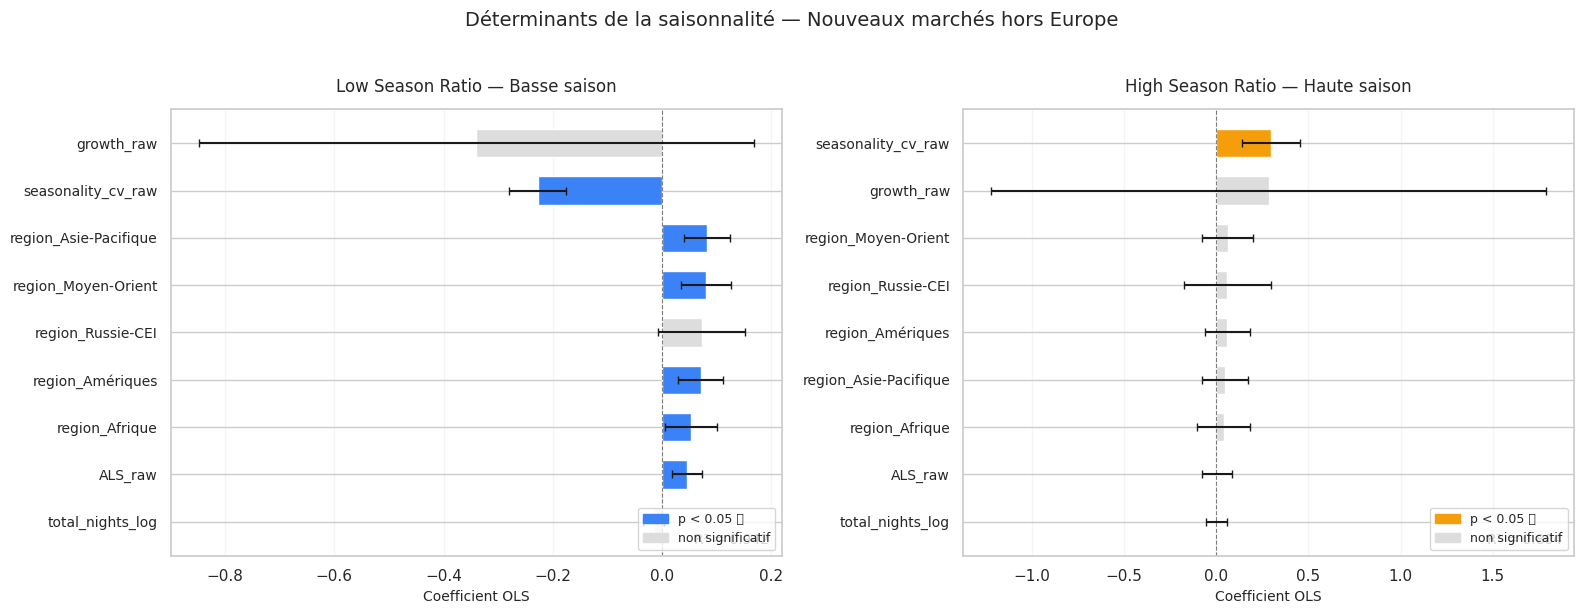

In [ ]:
# ============================================================
#  GRAPHIQUES DES COEFFICIENTS OLS
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

models     = [model_low,        model_high]
titles     = ["Low Season Ratio — Basse saison", "High Season Ratio — Haute saison"]
colors_sig = ["#3b82f6",        "#f59e0b"]

for ax, model, title, color_sig in zip(axes, models, titles, colors_sig):

    # Récupérer params sans constante
    coef  = pd.Series(model.params[1:],  index=feature_names[1:])
    pvals = pd.Series(model.pvalues[1:], index=feature_names[1:])
    conf  = pd.DataFrame(model.conf_int()[1:], index=feature_names[1:])

    # Trier par valeur absolue croissante
    order = coef.abs().sort_values(ascending=True).index
    coef  = coef[order]
    pvals = pvals[order]
    conf  = conf.loc[order]

    # Couleurs : significatif vs non significatif
    bar_colors = [color_sig if p < 0.05 else "#dddddd" for p in pvals]

    # Barres horizontales
    ax.barh(
        range(len(coef)),
        coef.values,
        xerr=[
            coef.values - conf[0].values,
            conf[1].values - coef.values
        ],
        color=bar_colors,
        edgecolor="white",
        height=0.6,
        capsize=3
    )

    # Ligne zéro
    ax.axvline(0, color="black", linewidth=0.8, linestyle="--", alpha=0.5)

    # Labels axes Y
    ax.set_yticks(range(len(coef)))
    ax.set_yticklabels(coef.index, fontsize=10)

    # Titre + R²
    ax.set_title(title, fontsize=12, pad=12)
    ax.set_xlabel("Coefficient OLS", fontsize=10)
    ax.text(
        0.98, 0.02, f"R² = {model.rsquared:.3f}",
        transform=ax.transAxes,
        ha="right", va="bottom", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="#f5f5f5", alpha=0.8)
    )

    # Légende
    patch_sig   = mpatches.Patch(color=color_sig, label="p < 0.05 ✅")
    patch_nosig = mpatches.Patch(color="#dddddd",  label="non significatif")
    ax.legend(handles=[patch_sig, patch_nosig], fontsize=9, loc="lower right")

    ax.grid(axis="x", alpha=0.2)

plt.suptitle(
    "Déterminants de la saisonnalité — Nouveaux marchés hors Europe",
    fontsize=14, y=1.02
)
plt.tight_layout()
plt.show()

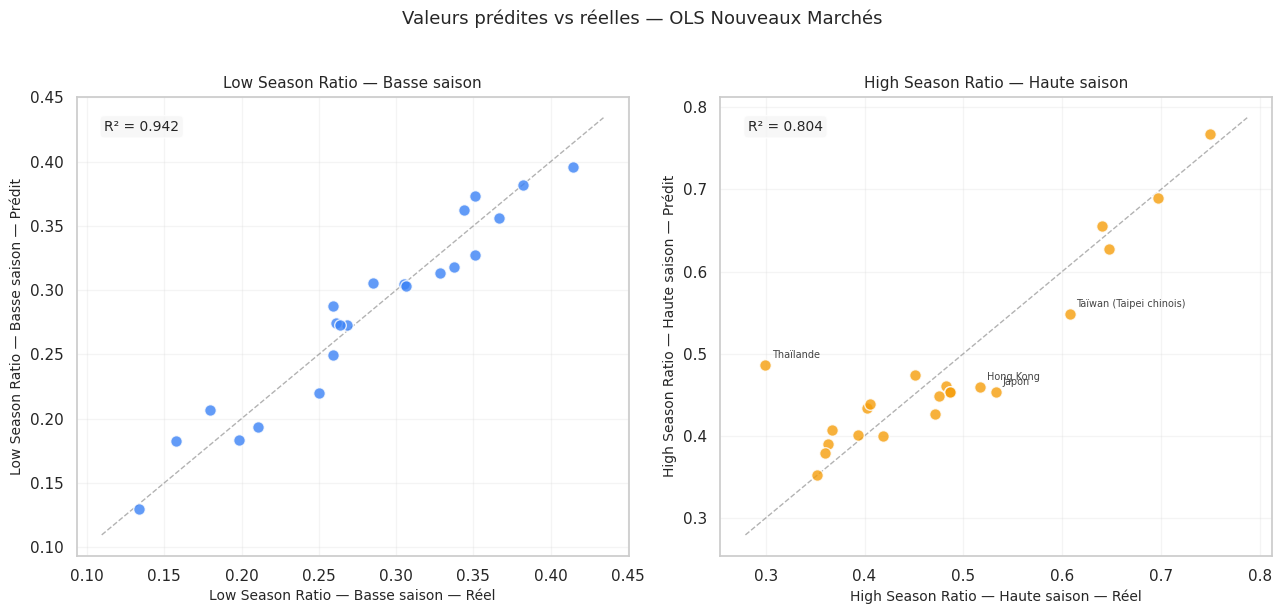

In [ ]:
# ============================================================
# SCATTER PRÉDIT VS RÉEL
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

configs = [
    (model_low,  y_low,  "Low Season Ratio — Basse saison",  "#3b82f6"),
    (model_high, y_high, "High Season Ratio — Haute saison", "#f59e0b"),
]

pays_list = df_reg["Pays"].reset_index(drop=True)

for ax, (model, y, label, color) in zip(axes, configs):

    # Prédictions via numpy
    X_np   = np.asarray(X.astype(float))
    y_np   = np.asarray(y.astype(float))
    y_pred = model.predict(X_np)

    # Scatter
    ax.scatter(
        y_np, y_pred,
        color=color, alpha=0.8,
        edgecolors="white", s=70, zorder=3
    )

    # Droite parfaite y=x
    lims = [
        min(y_np.min(), y_pred.min()) - 0.02,
        max(y_np.max(), y_pred.max()) + 0.02
    ]
    ax.plot(lims, lims, "--", color="grey", linewidth=1, alpha=0.6)

    # Annotation outliers (erreur > 0.05)
    for xi, yi, pays in zip(y_np, y_pred, pays_list):
        if abs(xi - yi) > 0.05:
            ax.annotate(
                pays,
                (xi, yi),
                fontsize=7,
                xytext=(5, 5),
                textcoords="offset points",
                color="#444444"
            )

    # Axes + titre
    ax.set_xlabel(f"{label} — Réel",   fontsize=10)
    ax.set_ylabel(f"{label} — Prédit", fontsize=10)
    ax.set_title(label, fontsize=11)
    ax.grid(alpha=0.2)

    # R² affiché
    ax.text(
        0.05, 0.95, f"R² = {model.rsquared:.3f}",
        transform=ax.transAxes,
        ha="left", va="top", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="#f5f5f5", alpha=0.8)
    )

plt.suptitle(
    "Valeurs prédites vs réelles — OLS Nouveaux Marchés",
    fontsize=13, y=1.02
)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1330/548296798.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", n_pays)


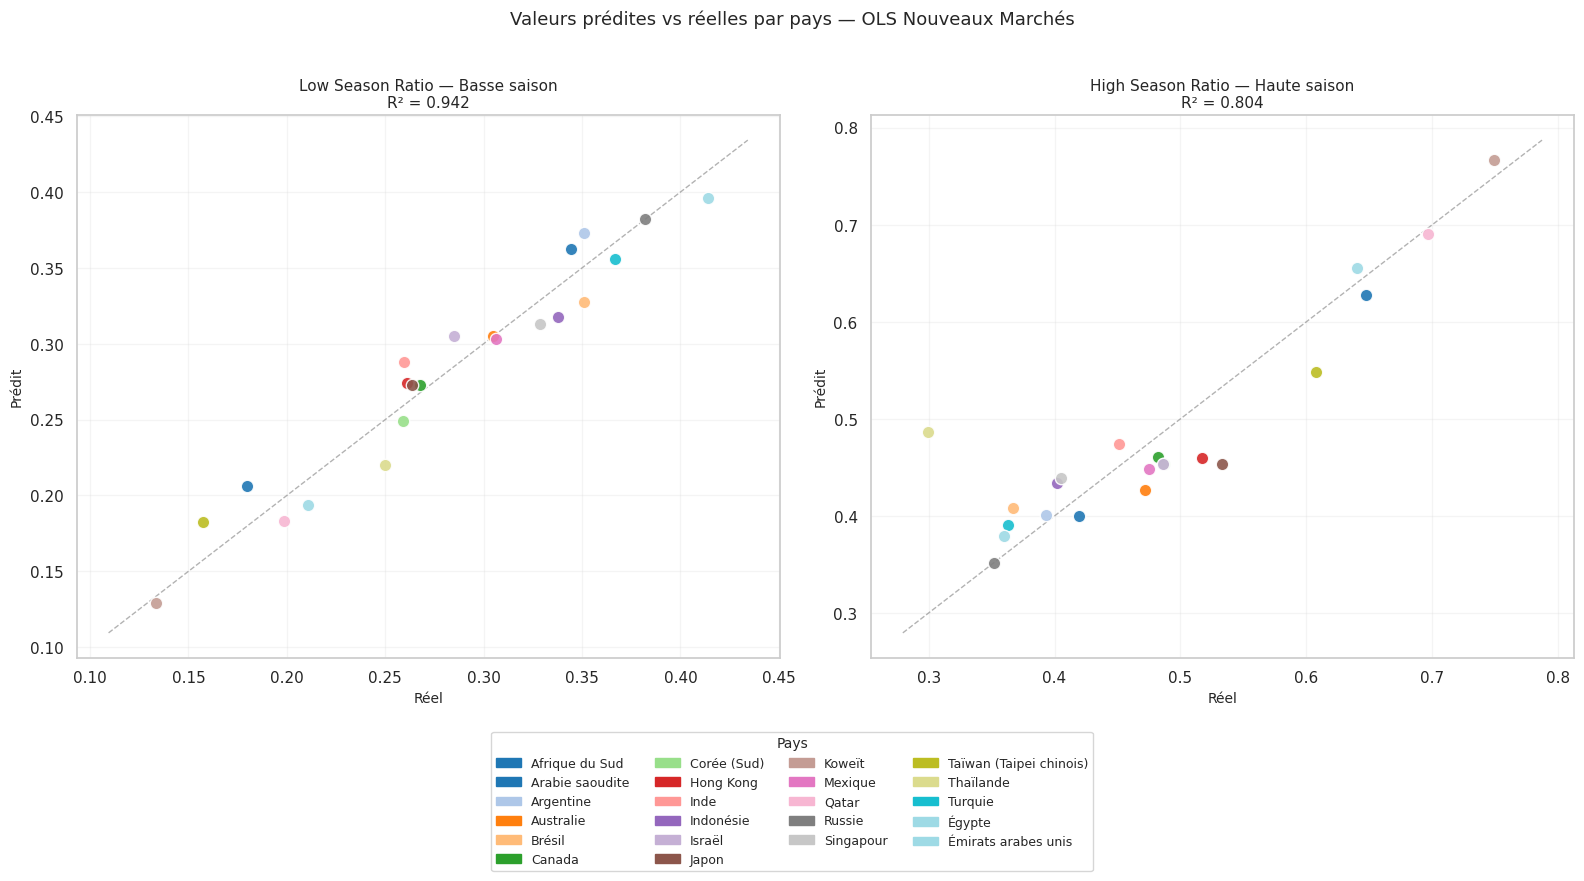

In [ ]:
# ============================================================
# CELLULE E — SCATTER AVEC COULEURS PAR PAYS
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# Palette de couleurs pour chaque pays
pays_list = df_reg["Pays"].reset_index(drop=True).tolist()
n_pays = len(pays_list)

cmap = plt.cm.get_cmap("tab20", n_pays)
country_colors = {pays: cmap(i) for i, pays in enumerate(pays_list)}

X_np = np.asarray(X.astype(float))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

configs = [
    (model_low,  y_low,  "Low Season Ratio — Basse saison"),
    (model_high, y_high, "High Season Ratio — Haute saison"),
]

for ax, (model, y, label) in zip(axes, configs):

    y_np   = np.asarray(y.astype(float))
    y_pred = model.predict(X_np)

    # Scatter un point par pays
    for xi, yi, pays in zip(y_np, y_pred, pays_list):
        ax.scatter(
            xi, yi,
            color=country_colors[pays],
            s=80, edgecolors="white",
            zorder=3, alpha=0.9
        )

    # Droite parfaite
    lims = [
        min(y_np.min(), y_pred.min()) - 0.02,
        max(y_np.max(), y_pred.max()) + 0.02
    ]
    ax.plot(lims, lims, "--", color="grey", linewidth=1, alpha=0.6)

    ax.set_xlabel(f"Réel",   fontsize=10)
    ax.set_ylabel(f"Prédit", fontsize=10)
    ax.set_title(f"{label}\nR² = {model.rsquared:.3f}", fontsize=11)
    ax.grid(alpha=0.2)

# Légende commune en bas — tous les pays
legend_patches = [
    mpatches.Patch(color=country_colors[pays], label=pays)
    for pays in pays_list
]

fig.legend(
    handles=legend_patches,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.22),
    ncol=4,
    fontsize=9,
    frameon=True,
    title="Pays",
    title_fontsize=10
)

plt.suptitle(
    "Valeurs prédites vs réelles par pays — OLS Nouveaux Marchés",
    fontsize=13, y=1.02
)
plt.tight_layout()
plt.show()

USELESS

In [ ]:
# ============================================================
# EXTRACTION DES VALEURS PAR PAYS
# ============================================================

import pandas as pd
import numpy as np

# Conversion numpy
X_np = np.asarray(X.astype(float))

# Prédictions
pred_low  = model_low.predict(X_np)
pred_high = model_high.predict(X_np)

# Tableau complet
df_graph = pd.DataFrame({
    "Pays": pays_list,

    # LOW SEASON
    "Low_Real":  np.asarray(y_low.astype(float)),
    "Low_Predit": pred_low,

    # HIGH SEASON
    "High_Real":  np.asarray(y_high.astype(float)),
    "High_Predit": pred_high,
})

# Affichage
print(df_graph)

# Export CSV
df_graph.to_csv("valeurs_graphes_par_pays.csv", index=False)

                       Pays  Low_Real  Low_Predit  High_Real  High_Predit
0            Afrique du Sud  0.344249    0.362483   0.419215     0.399909
1           Arabie saoudite  0.179688    0.206314   0.647688     0.627661
2                 Argentine  0.351170    0.373227   0.393384     0.400809
3                 Australie  0.305013    0.304924   0.471642     0.426732
4                    Brésil  0.351029    0.327321   0.367078     0.407751
5                    Canada  0.267929    0.272908   0.482464     0.460854
6               Corée (Sud)  0.259204    0.249176   0.486980     0.453565
7                 Hong Kong  0.260989    0.274102   0.516789     0.459514
8                      Inde  0.259344    0.287854   0.451464     0.473810
9                 Indonésie  0.337717    0.317638   0.402317     0.434035
10                   Israël  0.284943    0.305245   0.486496     0.453153
11                    Japon  0.263758    0.273089   0.532634     0.453236
12                   Koweït  0.133350 